In [53]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

# Define project directories
current_dir = Path.cwd()

if (current_dir / "data").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError("Project root not found.")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

# Load the employment Excel file
employment_file = RAW_DIR / "i_imt_txemp_02_data.xlsx"

excel_file = pd.ExcelFile(employment_file)

print("Available sheets:")
print(excel_file.sheet_names)


Available sheets:
['Data']


c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [54]:

# Inspect each available sheet
for sheet in excel_file.sheet_names:
    print(f"\n{'='*50}")
    print(f"Sheet: {sheet}")
    print(f"{'='*50}")

    df_preview = pd.read_excel(
        employment_file,
        sheet_name=sheet,
        header=None
    )

    print("Dimensions:", df_preview.shape)
    display(df_preview.head(10))



Sheet: Data
Dimensions: (214, 11)


,0,1,2,3,4,5,6,7,8,9,10
0,Taux d'emploi selon les Provinces/Préfectures ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Milieu,Provinces/Préfectures,2025,2024,2023,2022,2021,2020,2019,2018,2017
2,National,Al Hoceima,44.8,45.2,44.8,48.1,45.4,40.2,44.1,48.6,48.3
3,National,Chefchaouen,56.1,56.5,55.2,57.2,56,46.4,49.6,52.6,52.8
4,National,Fahs-Anjra,33.4,38.5,41,40.9,38.6,43.1,41.4,44.4,43.4
5,National,Larache,42.1,41.4,41.5,42.9,44.6,42.5,39.7,40.5,38.9
6,National,Ouezzane,44.3,44.7,47.9,50.4,51.7,44.7,39.8,41.7,43.6
7,National,Tanger-Assilah,39.6,41.2,41.9,41.2,39.9,39.9,39.5,39.6,38.4
8,National,Tétouan,41.7,41.1,41,43.9,43.9,41.7,41.6,41.6,41.9
9,National,M'Diq-Fnideq,38.4,36.5,37,39.4,38.8,38.5,41.8,41.8,42.2



## 3. Chargement des données avec les en-têtes corrects
« La première ligne du fichier contient le titre de l'indicateur, tandis que la deuxième ligne contient les noms des variables. Nous utilisons donc header=1 pour charger correctement les colonnes. »

In [55]:

# Load the employment dataset using the correct header row
df_employment_raw = pd.read_excel(
    employment_file,
    sheet_name="Data",
    header=1
)

print("Dataset dimensions:", df_employment_raw.shape)

print("\nColumn names:")
print(df_employment_raw.columns.tolist())

print("\nFirst 10 observations:")
display(df_employment_raw.head(10))

print("\nLast 10 observations:")
display(df_employment_raw.tail(10))


Dataset dimensions: (212, 11)

Column names:
['Milieu', 'Provinces/Préfectures', '2025', '2024', '2023', '2022', '2021', '2020', '2019', '2018', '2017']

First 10 observations:


c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Milieu,Provinces/Préfectures,2025,2024,2023,2022,2021,2020,2019,2018,2017
0,National,Al Hoceima,44.8,45.2,44.8,48.1,45.4,40.2,44.1,48.6,48.3
1,National,Chefchaouen,56.1,56.5,55.2,57.2,56,46.4,49.6,52.6,52.8
2,National,Fahs-Anjra,33.4,38.5,41,40.9,38.6,43.1,41.4,44.4,43.4
3,National,Larache,42.1,41.4,41.5,42.9,44.6,42.5,39.7,40.5,38.9
4,National,Ouezzane,44.3,44.7,47.9,50.4,51.7,44.7,39.8,41.7,43.6
5,National,Tanger-Assilah,39.6,41.2,41.9,41.2,39.9,39.9,39.5,39.6,38.4
6,National,Tétouan,41.7,41.1,41,43.9,43.9,41.7,41.6,41.6,41.9
7,National,M'Diq-Fnideq,38.4,36.5,37,39.4,38.8,38.5,41.8,41.8,42.2
8,National,Berkane,31.5,34,33.9,36.7,36.1,34.3,37.7,37.7,36.8
9,National,Driouch,31.5,29.9,30.9,34.5,36,34.2,38.3,36.7,37.2



Last 10 observations:


,Milieu,Provinces/Préfectures,2025,2024,2023,2022,2021,2020,2019,2018,2017
202,Rural,Zagora,37.1,35,36.9,33.3,38.8,36.1,41.3,35.1,33.4
203,Rural,Agadir-Ida-Ou-Tanane,32.6,32.6,33.9,35.1,41.3,41.1,41.3,38.8,46
204,Rural,Chtouka-Ait Baha,39.1,38.7,36.2,37.2,42.5,38.2,40.8,44.3,43.8
205,Rural,Inezgane-Ait Melloul,35.9,32.4,32.6,31.1,30.3,39.6,39.1,40.8,39.3
206,Rural,Taroudannt,35.1,34.9,33.3,34.9,39,40.2,43.6,45.2,45.8
207,Rural,Tata,29.7,28.1,20.8,21.7,27.3,33.9,33.3,34.1,32.7
208,Rural,Tiznit,24.2,24.8,25.7,25.4,32,31.4,31.5,32,35.4
209,Rural,Guelmim,33.8,27,31.5,33.1,40.6,37.8,46.8,41.8,44.1
210,Rural,Sidi Ifni,37.5,36.3,36.2,34.4,39.2,39.5,47.8,37.8,41.5
211,Rural,Oued Ed-Dahab,-,-,-,-,-,78.2,-,-,-


In [56]:

# Load and inspect the metadata workbook
employment_metadata_file = RAW_DIR / "i_imt_txemp_02_metadata.xlsx"

metadata_excel = pd.ExcelFile(employment_metadata_file)

print("Available metadata sheets:")
print(metadata_excel.sheet_names)

for sheet in metadata_excel.sheet_names:
    print(f"\nMetadata sheet: {sheet}")

    df_metadata_preview = pd.read_excel(
        employment_metadata_file,
        sheet_name=sheet,
        header=None
    )

    print("Dimensions:", df_metadata_preview.shape)
    display(df_metadata_preview.head(15))


Available metadata sheets:
['Metadata']

Metadata sheet: Metadata
Dimensions: (5, 2)


c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,0,1
0,L'indicateur,Taux d'emploi selon les Provinces/Préfectures ...
1,Définition,Taux d'emploi selon les Provinces/Préfectures ...
2,Périodicité,Annuelle
3,Unité,POURCENTAGE
4,Source,MAR_HCP ENQUETE NATIONALE SUR L'EMPLOI


In [57]:

# List all files available in the raw data folder
print("Files available in data/raw:\n")

for file in sorted(RAW_DIR.iterdir()):
    print(file.name)


Files available in data/raw:

i_i3287_data.xlsx
i_i3287_metadata.xlsx
i_i4249_data.xlsx
i_i4249_metadata.xlsx
i_imt_txch_02_data.xlsx
i_imt_txch_02_metadata.xlsx
i_imt_txemp_02_data.xlsx
i_imt_txemp_02_metadata.xlsx


In [58]:

# Examine geographical categories
print("Milieu categories:")
print(df_employment_raw["Milieu"].value_counts(dropna=False))

print("\nNumber of unique provinces/prefectures:")
print(df_employment_raw["Provinces/Préfectures"].nunique())

print("\nNumber of observations by milieu:")
display(
    df_employment_raw.groupby("Milieu")["Provinces/Préfectures"]
    .count()
)

print("\nMissing-value markers by year:")
year_cols = df_employment_raw.columns[2:]

for year in year_cols:
    count = df_employment_raw[year].astype(str).str.strip().eq("-").sum()
    print(f"{year}: {count}")


Milieu categories:
Milieu
National    74
Urbain      72
Rural       66
Name: count, dtype: int64

Number of unique provinces/prefectures:
74

Number of observations by milieu:


Milieu
National    74
Rural       66
Urbain      72
Name: Provinces/Préfectures, dtype: int64


Missing-value markers by year:
2025: 1
2024: 2
2023: 2
2022: 3
2021: 2
2020: 1
2019: 2
2018: 3
2017: 1


In [59]:

# Define the metadata file path
employment_metadata_file = RAW_DIR / "i_imt_txemp_02_metadata.xlsx"

# Read the available Excel sheets
metadata_excel = pd.ExcelFile(employment_metadata_file)

print("Available metadata sheets:")
print(metadata_excel.sheet_names)

# Inspect the content of each metadata sheet
for sheet in metadata_excel.sheet_names:
    print(f"\n{'='*50}")
    print(f"Metadata sheet: {sheet}")
    print(f"{'='*50}")

    df_metadata = pd.read_excel(
        employment_metadata_file,
        sheet_name=sheet,
        header=None
    )

    print("Dimensions:", df_metadata.shape)
    display(df_metadata.head(20))


Available metadata sheets:
['Metadata']

Metadata sheet: Metadata
Dimensions: (5, 2)


c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,0,1
0,L'indicateur,Taux d'emploi selon les Provinces/Préfectures ...
1,Définition,Taux d'emploi selon les Provinces/Préfectures ...
2,Périodicité,Annuelle
3,Unité,POURCENTAGE
4,Source,MAR_HCP ENQUETE NATIONALE SUR L'EMPLOI


In [60]:

# Identify unique geographical labels
print("Number of unique provinces/prefectures:")
print(df_employment_raw["Provinces/Préfectures"].nunique())

print("\nComplete list of geographical labels:")
display(
    pd.Series(
        sorted(df_employment_raw["Provinces/Préfectures"].dropna().unique()),
        name="Provinces/Préfectures"
    ).to_frame()
)

# Check duplicate geographical combinations
duplicate_geo = df_employment_raw.duplicated(
    subset=["Milieu", "Provinces/Préfectures"]
)

print("\nNumber of duplicate geographical combinations:")
print(duplicate_geo.sum())

if duplicate_geo.sum() > 0:
    display(
        df_employment_raw.loc[
            duplicate_geo,
            ["Milieu", "Provinces/Préfectures"]
        ]
    )


Number of unique provinces/prefectures:
74

Complete list of geographical labels:


,Provinces/Préfectures
0,Agadir-Ida-Ou-Tanane
1,Al Haouz
2,Al Hoceima
3,Assa-Zag
4,Azilal
...,...
69,Tinghir
70,Tiznit
71,Tétouan
72,Youssoufia



Number of duplicate geographical combinations:
0


In [61]:
# Count geographical labels for each residence category
for milieu in sorted(df_employment_raw["Milieu"].dropna().unique()):
    subset = df_employment_raw[
        df_employment_raw["Milieu"] == milieu
    ]

    print(f"\nMilieu: {milieu}")
    print("Number of provinces/prefectures:", 
          subset["Provinces/Préfectures"].nunique())

    print("Missing geographical labels:",
          subset["Provinces/Préfectures"].isna().sum())

    print("Territories:")
    print(
        subset["Provinces/Préfectures"]
        .dropna()
        .sort_values()
        .to_string(index=False)
    )


Milieu: National
Number of provinces/prefectures: 74
Missing geographical labels: 0
Territories:
Agadir-Ida-Ou-Tanane
            Al Haouz
          Al Hoceima
            Assa-Zag
              Azilal
          Benslimane
             Berkane
           Berrechid
            Boujdour
           Boulemane
         Béni Mellal
          Casablanca
         Chefchaouen
           Chichaoua
    Chtouka-Ait Baha
             Driouch
            El Hajeb
           El Jadida
El Kelâa des Sraghna
          Errachidia
           Es-Semara
           Essaouira
          Fahs-Anjra
              Figuig
     Fquih Ben Salah
                 Fès
             Guelmim
             Guercif
              Ifrane
Inezgane-Ait Melloul
              Jerada
           Khouribga
           Khémisset
            Khénifra
             Kénitra
             Larache
            Laâyoune
        M'Diq-Fnideq
           Marrakech
              Meknès
              Midelt
          Mohammadia
       Moulay Yacoub

In [62]:
# Load the cleaned provincial unemployment dataset
unemployment_file = PROCESSED_DIR / "i_imt_txch_02_cleaned.csv"

df_unemployment_province = pd.read_csv(unemployment_file)

# Create sets of geographical labels
employment_territories = set(
    df_employment_raw["Provinces/Préfectures"]
    .dropna()
    .str.strip()
)

unemployment_territories = set(
    df_unemployment_province["Provinces/Préfectures"]
    .dropna()
    .str.strip()
)

# Compare geographical coverage
common_territories = employment_territories & unemployment_territories

employment_only = employment_territories - unemployment_territories
unemployment_only = unemployment_territories - employment_territories

print("Employment territories:", len(employment_territories))
print("Unemployment territories:", len(unemployment_territories))
print("Common territories:", len(common_territories))

print("\nTerritories only in employment dataset:")
print(sorted(employment_only))

print("\nTerritories only in unemployment dataset:")
print(sorted(unemployment_only))

Employment territories: 74
Unemployment territories: 71
Common territories: 71

Territories only in employment dataset:
['Assa-Zag', 'Fahs-Anjra', 'Tarfaya']

Territories only in unemployment dataset:
[]


In [63]:
# Identify annual columns
year_cols = [
    col for col in df_employment_raw.columns
    if str(col).isdigit()
]

print("Annual columns:", year_cols)

# Inspect data types
print("\nData types:")
print(df_employment_raw[year_cols].dtypes)

# Detect non-numeric values in annual columns
for year in year_cols:
    numeric_values = pd.to_numeric(
        df_employment_raw[year],
        errors="coerce"
    )

    original_values = df_employment_raw[year].astype(str).str.strip()

    unexpected_values = original_values[
        numeric_values.isna() & (original_values != "-")
    ].unique()

    print(f"\nYear: {year}")
    print("Missing values:", df_employment_raw[year].isna().sum())
    print("Dash markers:", (original_values == "-").sum())
    print("Unexpected non-numeric values:", unexpected_values)

Annual columns: ['2025', '2024', '2023', '2022', '2021', '2020', '2019', '2018', '2017']

Data types:
2025    object
2024    object
2023    object
2022    object
2021    object
2020    object
2019    object
2018    object
2017    object
dtype: object

Year: 2025
Missing values: 0
Dash markers: 1
Unexpected non-numeric values: <ArrowStringArray>
[]
Length: 0, dtype: str

Year: 2024
Missing values: 0
Dash markers: 2
Unexpected non-numeric values: <ArrowStringArray>
[]
Length: 0, dtype: str

Year: 2023
Missing values: 0
Dash markers: 2
Unexpected non-numeric values: <ArrowStringArray>
[]
Length: 0, dtype: str

Year: 2022
Missing values: 0
Dash markers: 3
Unexpected non-numeric values: <ArrowStringArray>
[]
Length: 0, dtype: str

Year: 2021
Missing values: 0
Dash markers: 2
Unexpected non-numeric values: <ArrowStringArray>
[]
Length: 0, dtype: str

Year: 2020
Missing values: 0
Dash markers: 1
Unexpected non-numeric values: <ArrowStringArray>
[]
Length: 0, dtype: str

Year: 2019
Missing val

In [64]:
# Create a copy to preserve the original dataset
df_employment_clean = df_employment_raw.copy()

# Clean geographical text columns
text_cols = ["Milieu", "Provinces/Préfectures"]

for col in text_cols:
    df_employment_clean[col] = (
        df_employment_clean[col]
        .astype("string")
        .str.strip()
    )

# Replace dash markers with missing values
df_employment_clean[year_cols] = (
    df_employment_clean[year_cols]
    .replace("-", np.nan)
)

# Convert annual columns to numeric
df_employment_clean[year_cols] = (
    df_employment_clean[year_cols]
    .apply(pd.to_numeric, errors="coerce")
)

print("Cleaning completed.")
print("Dataset shape:", df_employment_clean.shape)

print("\nData types:")
print(df_employment_clean.dtypes)

Cleaning completed.
Dataset shape: (212, 11)

Data types:
Milieu                    string
Provinces/Préfectures     string
2025                     float64
2024                     float64
2023                     float64
2022                     float64
2021                     float64
2020                     float64
2019                     float64
2018                     float64
2017                     float64
dtype: object


In [65]:
# Check missing values
print("Missing values by column:")
display(df_employment_clean.isna().sum().to_frame("Missing values"))

# Check total missing values
print("\nTotal missing values:")
print(df_employment_clean.isna().sum().sum())

# Check numerical ranges
print("\nAnnual statistical summary:")
display(df_employment_clean[year_cols].describe())

# Check values outside the expected percentage range
invalid_values = (
    (df_employment_clean[year_cols] < 0)
    | (df_employment_clean[year_cols] > 100)
)

print("\nNumber of values outside 0-100%:")
print(invalid_values.sum().sum())

# Check duplicate geographical combinations
print("\nDuplicate geographical combinations:")
print(
    df_employment_clean.duplicated(
        subset=["Milieu", "Provinces/Préfectures"]
    ).sum()
)

Missing values by column:


,Missing values
Milieu,0
Provinces/Préfectures,0
2025,1
2024,2
2023,2
2022,3
2021,2
2020,1
2019,2
2018,3



Total missing values:
17

Annual statistical summary:


,2025,2024,2023,2022,2021,2020,2019,2018,2017
count,211.000000,210.000000,210.000000,209.000000,210.000000,211.000000,210.000000,209.000000,211.000000
mean,37.690995,37.343810,37.767619,39.048804,40.053810,39.711848,41.618571,42.005263,42.158768
std,6.585205,6.733838,7.055854,7.521138,7.673556,7.584439,8.173700,8.874933,9.186411
min,24.100000,21.100000,20.800000,21.700000,22.800000,27.900000,24.800000,25.800000,23.800000
25%,33.650000,32.600000,32.900000,33.800000,34.550000,34.300000,36.100000,35.600000,35.250000
50%,37.200000,36.600000,36.950000,38.100000,38.650000,38.400000,40.450000,40.800000,40.600000
75%,41.050000,41.100000,41.650000,42.900000,44.675000,44.000000,46.575000,46.800000,47.300000
max,60.700000,61.400000,59.700000,62.000000,63.900000,78.200000,70.300000,71.300000,74.700000



Number of values outside 0-100%:
0

Duplicate geographical combinations:
0


In [66]:
# Calculate missing values for each year
missing_by_year = pd.DataFrame({
    "Annee": year_cols,
    "Valeurs_manquantes": [
        df_employment_clean[year].isna().sum()
        for year in year_cols
    ]
})

missing_by_year["Taux_manquants_pct"] = (
    missing_by_year["Valeurs_manquantes"]
    / len(df_employment_clean)
    * 100
)

display(missing_by_year)

,Annee,Valeurs_manquantes,Taux_manquants_pct
0,2025,1,0.471698
1,2024,2,0.943396
2,2023,2,0.943396
3,2022,3,1.415094
4,2021,2,0.943396
5,2020,1,0.471698
6,2019,2,0.943396
7,2018,3,1.415094
8,2017,1,0.471698


In [67]:
# Define the output path
employment_cleaned_file = (
    PROCESSED_DIR / "i_imt_txemp_02_cleaned.csv"
)

# Export the cleaned dataset
df_employment_clean.to_csv(
    employment_cleaned_file,
    index=False,
    encoding="utf-8-sig"
)

print("Cleaned dataset exported successfully.")
print("File:", employment_cleaned_file)
print("Shape:", df_employment_clean.shape)

Cleaned dataset exported successfully.
File: c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\data\processed\i_imt_txemp_02_cleaned.csv
Shape: (212, 11)


In [68]:
# Transform the dataset from wide to long format
df_employment_long = df_employment_clean.melt(
    id_vars=["Milieu", "Provinces/Préfectures"],
    value_vars=year_cols,
    var_name="Annee",
    value_name="Taux_emploi"
)

# Convert year to integer
df_employment_long["Annee"] = (
    df_employment_long["Annee"].astype(int)
)

# Sort chronologically by territory and year
df_employment_long = df_employment_long.sort_values(
    by=["Milieu", "Provinces/Préfectures", "Annee"]
).reset_index(drop=True)

print("Long-format dataset created.")
print("Shape:", df_employment_long.shape)

display(df_employment_long.head(10))

Long-format dataset created.
Shape: (1908, 4)


,Milieu,Provinces/Préfectures,Annee,Taux_emploi
0,National,Agadir-Ida-Ou-Tanane,2017,36.2
1,National,Agadir-Ida-Ou-Tanane,2018,34.9
2,National,Agadir-Ida-Ou-Tanane,2019,36.3
3,National,Agadir-Ida-Ou-Tanane,2020,35.1
4,National,Agadir-Ida-Ou-Tanane,2021,34.5
5,National,Agadir-Ida-Ou-Tanane,2022,32.3
6,National,Agadir-Ida-Ou-Tanane,2023,33.1
7,National,Agadir-Ida-Ou-Tanane,2024,34.8
8,National,Agadir-Ida-Ou-Tanane,2025,35.3
9,National,Al Haouz,2017,47.3


In [69]:
# Check dimensions and data types
print("Dataset shape:", df_employment_long.shape)

print("\nData types:")
print(df_employment_long.dtypes)

# Check missing values
print("\nMissing values:")
print(df_employment_long.isna().sum())

# Check duplicate observations
duplicate_count = df_employment_long.duplicated(
    subset=[
        "Milieu",
        "Provinces/Préfectures",
        "Annee"
    ]
).sum()

print("\nDuplicate observations:", duplicate_count)

# Check year coverage
print("\nYear range:")
print(
    df_employment_long["Annee"].min(),
    "to",
    df_employment_long["Annee"].max()
)

print("\nNumber of observations per year:")
display(
    df_employment_long.groupby("Annee")["Taux_emploi"]
    .count()
    .to_frame("Available observations")
)

Dataset shape: (1908, 4)

Data types:
Milieu                    string
Provinces/Préfectures     string
Annee                      int64
Taux_emploi              float64
dtype: object

Missing values:
Milieu                    0
Provinces/Préfectures     0
Annee                     0
Taux_emploi              17
dtype: int64

Duplicate observations: 0

Year range:
2017 to 2025

Number of observations per year:


,Available observations
Annee,
2017,211
2018,209
2019,210
2020,211
2021,210
2022,209
2023,210
2024,210
2025,211


In [70]:
# Define the output path
employment_long_file = (
    PROCESSED_DIR / "i_imt_txemp_02_long.csv"
)

# Export the long-format dataset
df_employment_long.to_csv(
    employment_long_file,
    index=False,
    encoding="utf-8-sig"
)

print("Long-format dataset exported successfully.")
print("File:", employment_long_file)
print("Shape:", df_employment_long.shape)

Long-format dataset exported successfully.
File: c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\data\processed\i_imt_txemp_02_long.csv
Shape: (1908, 4)


In [71]:
# Count records and unique territories by residence category
milieu_summary = (
    df_employment_long
    .groupby("Milieu")
    .agg(
        Nombre_territoires=("Provinces/Préfectures", "nunique"),
        Nombre_observations=("Taux_emploi", "count"),
        Nombre_lignes=("Annee", "size")
    )
)

display(milieu_summary)

,Nombre_territoires,Nombre_observations,Nombre_lignes
Milieu,,,
National,74,659,666
Rural,66,586,594
Urbain,72,646,648


In [72]:
# Calculate descriptive statistics by residence category and year
employment_stats = (
    df_employment_long
    .groupby(["Milieu", "Annee"])["Taux_emploi"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(employment_stats)

count   mean  median   std   min   max
Milieu   Annee                                        
National 2017      74  41.99   41.65  7.30  23.8  66.6
         2018      73  41.89   41.10  6.98  30.7  64.8
         2019      73  41.42   41.00  6.39  24.8  60.5
         2020      73  39.36   39.10  5.49  28.9  56.1
         2021      73  39.93   39.60  5.83  28.5  56.9
         2022      73  39.00   39.20  6.16  25.5  57.2
         2023      73  37.72   37.80  6.00  23.0  56.5
         2024      73  37.34   37.60  5.78  23.3  56.5
         2025      74  37.61   37.70  5.74  25.0  56.1
Rural    2017      65  50.05   48.70  8.59  32.7  74.7
         2018      65  49.26   48.90  8.76  32.0  71.3
         2019      65  48.48   47.80  8.00  31.5  70.3
         2020      66  45.86   46.35  8.16  31.4  78.2
         2021      65  46.38   46.00  7.80  27.3  63.9
         2022      65  44.20   43.50  8.51  21.7  62.0
         2023      65  42.34   42.10  7.69  20.8  59.7
         2024      65  41.35   40.90  7.68  24.8  61.4
         2025      65  41.41   40.40  7.46  24.2  60.7
Urbain   2017      72  35.21   34.80  4.73  23.8  49.4
         2018      71  35.48   35.60  4.68  25.8  51.0
         2019      72  35.62   35.85  4.23  24.8  47.9
         2020      72  34.43   34.45  3.88  27.9  45.2
         2021      72  34.47   34.70  3.95  22.8  44.8
         2022      71  34.38   35.00  4.02  25.9  44.4
         2023      72  33.69   33.50  4.55  23.0  47.3
         2024      72  33.74   34.45  4.31  21.1  44.3
         2025      72  34.42   34.95  4.54  24.1  47.9

In [73]:
# Filter national employment rates for 2025
df_employment_2025 = df_employment_long[
    (df_employment_long["Milieu"] == "National") &
    (df_employment_long["Annee"] == 2025)
].copy()

# Remove missing employment rates
df_employment_2025 = df_employment_2025.dropna(
    subset=["Taux_emploi"]
)

# Sort territories by employment rate
df_employment_2025_sorted = df_employment_2025.sort_values(
    by="Taux_emploi",
    ascending=False
)

# Display the 10 highest employment rates
print("Top 10 provinces/prefectures - Employment rate 2025")
display(df_employment_2025_sorted.head(10))

# Display the 10 lowest employment rates
print("Bottom 10 provinces/prefectures - Employment rate 2025")
display(df_employment_2025_sorted.tail(10))

print("\nNumber of territories with available data:",
      len(df_employment_2025))

Top 10 provinces/prefectures - Employment rate 2025


,Milieu,Provinces/Préfectures,Annee,Taux_emploi
116,National,Chefchaouen,2025,56.1
431,National,Oued Ed-Dahab,2025,53.2
512,National,Sidi Bennour,2025,50.1
161,National,El Jadida,2025,45.3
26,National,Al Hoceima,2025,44.8
260,National,Ifrane,2025,44.7
413,National,Nouaceur,2025,44.4
440,National,Ouezzane,2025,44.3
386,National,Moulay Yacoub,2025,44.1
593,National,Tarfaya,2025,43.3


Bottom 10 provinces/prefectures - Employment rate 2025


,Milieu,Provinces/Préfectures,Annee,Taux_emploi
404,National,Nador,2025,31.3
242,National,Guelmim,2025,30.8
179,National,Errachidia,2025,30.7
584,National,Taourirt,2025,30.6
332,National,Laâyoune,2025,30.0
449,National,Oujda-Angad,2025,29.1
638,National,Tiznit,2025,29.0
188,National,Es-Semara,2025,27.1
44,National,Azilal,2025,25.4
35,National,Assa-Zag,2025,25.0



Number of territories with available data: 74


In [74]:
# Identify territories with complete observations in all nine years
balanced_panels = {}

for milieu in sorted(df_employment_long["Milieu"].unique()):

    df_subset = df_employment_long[
        df_employment_long["Milieu"] == milieu
    ]

    # Create a territory-by-year table
    df_pivot = df_subset.pivot(
        index="Provinces/Préfectures",
        columns="Annee",
        values="Taux_emploi"
    )

    # Keep only territories with no missing annual values
    df_complete = df_pivot.dropna()

    balanced_panels[milieu] = df_complete

    print(f"\nMilieu: {milieu}")
    print("Total territories:", len(df_pivot))
    print("Complete territories:", len(df_complete))
    print("Incomplete territories:", len(df_pivot) - len(df_complete))


Milieu: National
Total territories: 74
Complete territories: 72
Incomplete territories: 2

Milieu: Rural
Total territories: 66
Complete territories: 65
Incomplete territories: 1

Milieu: Urbain
Total territories: 72
Complete territories: 70
Incomplete territories: 2


In [75]:
# Calculate annual statistics using balanced panels
balanced_stats = []

for milieu, df_complete in balanced_panels.items():

    for year in df_complete.columns:

        balanced_stats.append({
            "Milieu": milieu,
            "Annee": year,
            "Nombre_territoires": len(df_complete),
            "Moyenne": df_complete[year].mean(),
            "Mediane": df_complete[year].median()
        })

df_balanced_stats = pd.DataFrame(balanced_stats)

df_balanced_stats[
    ["Moyenne", "Mediane"]
] = df_balanced_stats[
    ["Moyenne", "Mediane"]
].round(2)

display(df_balanced_stats)

,Milieu,Annee,Nombre_territoires,Moyenne,Mediane
0,National,2017,72,42.26,41.85
1,National,2018,72,42.02,41.10
2,National,2019,72,41.65,41.15
3,National,2020,72,39.48,39.30
4,National,2021,72,40.09,39.65
5,National,2022,72,39.16,39.25
6,National,2023,72,37.92,37.85
7,National,2024,72,37.53,37.85
8,National,2025,72,37.70,37.70
9,Rural,2017,65,50.05,48.70


In [76]:
# Compare 2017 and 2025 using the same territories
balanced_evolution = []

for milieu, df_complete in balanced_panels.items():

    mean_2017 = df_complete[2017].mean()
    mean_2025 = df_complete[2025].mean()

    median_2017 = df_complete[2017].median()
    median_2025 = df_complete[2025].median()

    balanced_evolution.append({
        "Milieu": milieu,
        "Nombre_territoires": len(df_complete),
        "Moyenne_2017": mean_2017,
        "Moyenne_2025": mean_2025,
        "Variation_moyenne_pp": mean_2025 - mean_2017,
        "Mediane_2017": median_2017,
        "Mediane_2025": median_2025,
        "Variation_mediane_pp": median_2025 - median_2017
    })

df_balanced_evolution = pd.DataFrame(balanced_evolution)

display(df_balanced_evolution.round(2))

,Milieu,Nombre_territoires,Moyenne_2017,Moyenne_2025,Variation_moyenne_pp,Mediane_2017,Mediane_2025,Variation_mediane_pp
0,National,72,42.26,37.70,-4.55,41.85,37.70,-4.15
1,Rural,65,50.05,41.41,-8.64,48.70,40.40,-8.30
2,Urbain,70,35.34,34.46,-0.88,34.80,34.95,0.15


In [77]:
# Find the highest rural employment rate
df_rural = df_employment_long[
    df_employment_long["Milieu"] == "Rural"
].dropna(subset=["Taux_emploi"])

max_rural = df_rural.loc[
    df_rural["Taux_emploi"].idxmax()
]

print("Highest rural employment rate:")
display(max_rural.to_frame("Value"))

# Inspect the same territory across all available years
territory = max_rural["Provinces/Préfectures"]

df_extreme_territory = df_rural[
    df_rural["Provinces/Préfectures"] == territory
].sort_values("Annee")

print("\nHistorical evolution of this territory:")
display(df_extreme_territory)

Highest rural employment rate:


,Value
Milieu,Rural
Provinces/Préfectures,Oued Ed-Dahab
Annee,2020
Taux_emploi,78.2



Historical evolution of this territory:


,Milieu,Provinces/Préfectures,Annee,Taux_emploi
1047,Rural,Oued Ed-Dahab,2020,78.2


## Une Interpretation du notebook 
L'analyse du panel équilibré entre 2017 et 2025 met en évidence une diminution de la moyenne des taux d'emploi dans les trois milieux étudiés. Cette baisse est particulièrement marquée dans le milieu rural, où la moyenne territoriale recule de 8,64 points de pourcentage. Dans le milieu urbain, la diminution est plus limitée, avec une variation de −0,88 point, tandis que la médiane augmente légèrement de 0,15 point. Ces résultats révèlent des évolutions territoriales différenciées. Ils reposent toutefois sur des moyennes non pondérées et ne représentent pas directement les taux d'emploi agrégés de la population marocaine.

In [78]:
# Identify territories with incomplete annual observations
for milieu in sorted(df_employment_long["Milieu"].unique()):

    df_subset = df_employment_long[
        df_employment_long["Milieu"] == milieu
    ]

    df_pivot = df_subset.pivot(
        index="Provinces/Préfectures",
        columns="Annee",
        values="Taux_emploi"
    )

    incomplete = df_pivot[df_pivot.isna().any(axis=1)]

    print(f"\nMilieu: {milieu}")
    print("Incomplete territories:", len(incomplete))

    display(incomplete)


Milieu: National
Incomplete territories: 2


Annee,2017,2018,2019,2020,2021,2022,2023,2024,2025
Provinces/Préfectures,,,,,,,,,
Assa-Zag,23.8,NaN,24.8,31.4,28.5,27.4,23.0,23.3,25.0
Tarfaya,41.4,32.3,NaN,NaN,NaN,NaN,NaN,NaN,43.3



Milieu: Rural
Incomplete territories: 1


Annee,2017,2018,2019,2020,2021,2022,2023,2024,2025
Provinces/Préfectures,,,,,,,,,
Oued Ed-Dahab,NaN,NaN,NaN,78.2,NaN,NaN,NaN,NaN,NaN



Milieu: Urbain
Incomplete territories: 2


Annee,2017,2018,2019,2020,2021,2022,2023,2024,2025
Provinces/Préfectures,,,,,,,,,
Assa-Zag,23.8,NaN,24.8,31.4,28.5,27.4,23.0,23.3,25.0
Moulay Yacoub,37.2,42.8,31.8,35.8,36.0,NaN,33.9,31.7,41.3


In [79]:
# Inspect Oued Ed-Dahab in the original dataset
oued_ed_dahab_raw = df_employment_raw[
    df_employment_raw["Provinces/Préfectures"]
    .str.strip()
    .eq("Oued Ed-Dahab")
]

print("Original Excel records:")
display(oued_ed_dahab_raw)

# Inspect the cleaned records
oued_ed_dahab_clean = df_employment_clean[
    df_employment_clean["Provinces/Préfectures"]
    .eq("Oued Ed-Dahab")
]

print("\nCleaned records:")
display(oued_ed_dahab_clean)

Original Excel records:


,Milieu,Provinces/Préfectures,2025,2024,2023,2022,2021,2020,2019,2018,2017
73,National,Oued Ed-Dahab,53.2,53,56.5,53.8,49.7,50.6,60,64.7,66.6
145,Urbain,Oued Ed-Dahab,47.9,44.3,47.3,44.4,44.8,44.2,47.9,50.2,49.4
211,Rural,Oued Ed-Dahab,-,-,-,-,-,78.2,-,-,-



Cleaned records:


,Milieu,Provinces/Préfectures,2025,2024,2023,2022,2021,2020,2019,2018,2017
73,National,Oued Ed-Dahab,53.2,53.0,56.5,53.8,49.7,50.6,60.0,64.7,66.6
145,Urbain,Oued Ed-Dahab,47.9,44.3,47.3,44.4,44.8,44.2,47.9,50.2,49.4
211,Rural,Oued Ed-Dahab,NaN,NaN,NaN,NaN,NaN,78.2,NaN,NaN,NaN


In [80]:
# Identify employment rates above 65%
high_employment_rates = (
    df_employment_long[
        df_employment_long["Taux_emploi"] > 65
    ]
    .sort_values(
        by="Taux_emploi",
        ascending=False
    )
)

print("Number of observations above 65%:",
      len(high_employment_rates))

display(high_employment_rates)

Number of observations above 65%: 17


,Milieu,Provinces/Préfectures,Annee,Taux_emploi
1047,Rural,Oued Ed-Dahab,2020,78.2
702,Rural,Benslimane,2017,74.7
1116,Rural,Sidi Bennour,2017,71.8
703,Rural,Benslimane,2018,71.3
1117,Rural,Sidi Bennour,2018,71.0
929,Rural,Khénifra,2019,70.3
928,Rural,Khénifra,2018,70.1
909,Rural,Khouribga,2017,68.3
927,Rural,Khénifra,2017,67.2
792,Rural,El Jadida,2017,66.9


## Maintenant le Calcul et visualisation des moyennes annuelles

In [81]:
# Calculate the annual mean employment rate for each balanced panel

employment_trends = {}

for milieu, df_panel in balanced_panels.items():
    employment_trends[milieu] = df_panel.mean(axis=0)

df_employment_trends = pd.DataFrame(employment_trends)

# Display the annual mean employment rates
display(df_employment_trends)

,National,Rural,Urbain
Annee,,,
2017,42.255556,50.046154,35.341429
2018,42.020833,49.261538,35.378571
2019,41.654167,48.481538,35.830000
2020,39.475000,45.358462,34.455714
2021,40.086111,46.384615,34.530000
2022,39.162500,44.196923,34.484286
2023,37.919444,42.340000,33.842857
2024,37.530556,41.349231,33.914286
2025,37.701389,41.410769,34.457143


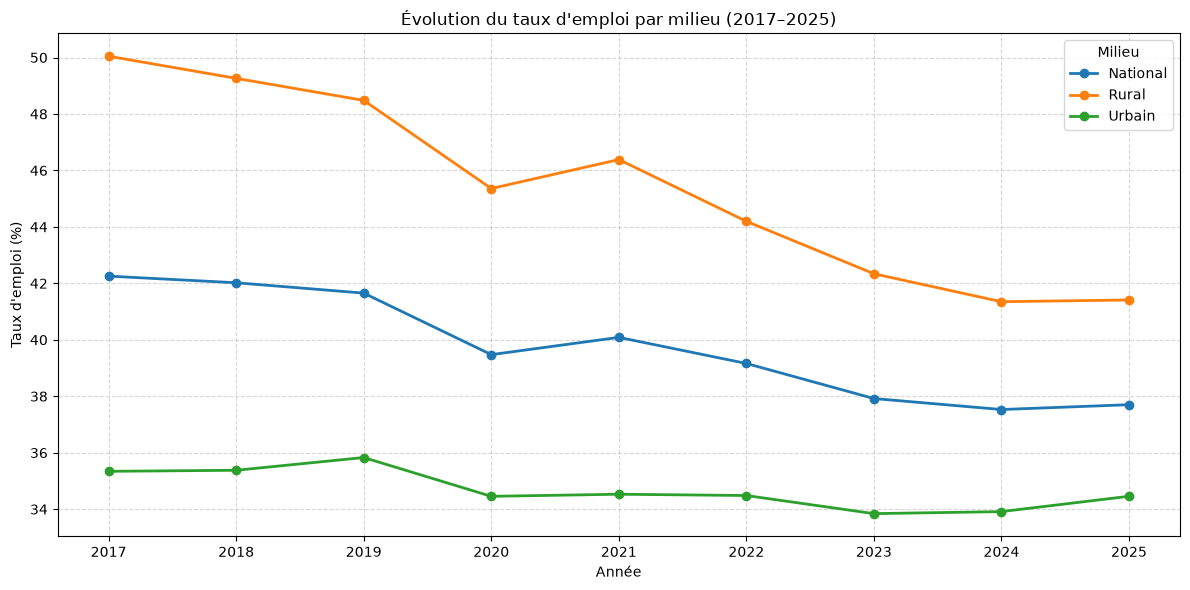

In [82]:
import matplotlib.pyplot as plt

# Create the figure
plt.figure(figsize=(12, 6))

# Plot the three employment trends
for milieu in df_employment_trends.columns:
    plt.plot(
        df_employment_trends.index,
        df_employment_trends[milieu],
        marker="o",
        linewidth=2,
        label=milieu
    )

# Add titles and labels
plt.title("Évolution du taux d'emploi par milieu (2017–2025)")
plt.xlabel("Année")
plt.ylabel("Taux d'emploi (%)")

# Improve readability
plt.xticks(df_employment_trends.index)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Milieu")

plt.tight_layout()

# Save the figure
plt.savefig(
    FIGURES_DIR / "employment_trend_by_milieu_2017_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

L'évolution des taux d'emploi moyens entre 2017 et 2025 met en évidence des trajectoires différenciées selon le milieu de résidence. Le milieu rural présente la diminution la plus importante, avec une baisse de 8,64 points de pourcentage, contre 0,88 point dans le milieu urbain. Une diminution simultanée des moyennes est observée entre 2019 et 2020, suivie d'une reprise limitée en 2021. Les moyennes diminuent ensuite jusqu'en 2024, avant d'enregistrer une légère remontée en 2025. L'écart entre les moyennes rurales et urbaines se réduit sur la période étudiée. Ces résultats reposent sur des moyennes territoriales non pondérées calculées à partir de panels équilibrés ; ils ne représentent donc pas directement les taux d'emploi agrégés de la population marocaine. Cette analyse descriptive ne permet pas, à elle seule, d'identifier les causes des évolutions observées.

In [83]:
# Calculate year-to-year changes in employment rates
df_employment_annual_changes = (
    df_employment_trends.diff()
    .iloc[1:]
    .copy()
)

# Replace year indexes with transition labels
df_employment_annual_changes.index = [
    f"{year - 1}-{year}"
    for year in df_employment_trends.index[1:]
]

# Display annual changes in percentage points
display(df_employment_annual_changes.round(2))

,National,Rural,Urbain
2017-2018,-0.23,-0.78,0.04
2018-2019,-0.37,-0.78,0.45
2019-2020,-2.18,-3.12,-1.37
2020-2021,0.61,1.03,0.07
2021-2022,-0.92,-2.19,-0.05
2022-2023,-1.24,-1.86,-0.64
2023-2024,-0.39,-0.99,0.07
2024-2025,0.17,0.06,0.54


In [84]:
# Summarize the direction of annual changes for each milieu
change_summary = pd.DataFrame({
    "Augmentations": (df_employment_annual_changes > 0).sum(),
    "Diminutions": (df_employment_annual_changes < 0).sum(),
    "Stabilite": (df_employment_annual_changes == 0).sum()
})

# Display the results
display(change_summary)

,Augmentations,Diminutions,Stabilite
National,2,6,0
Rural,2,6,0
Urbain,5,3,0


L'analyse des variations annuelles révèle une prédominance des diminutions dans les milieux national et rural, avec six transitions négatives sur huit pour chacun d'eux. En revanche, le milieu urbain présente cinq transitions positives contre trois négatives. La période 2019–2020 se distingue par une baisse simultanée des taux d'emploi moyens dans les trois milieux, particulièrement dans le milieu rural, où la diminution atteint 3,12 points de pourcentage. Une légère reprise est observée entre 2024 et 2025 dans les trois milieux. Ces résultats mettent en évidence des dynamiques temporelles différenciées selon le milieu de résidence. Ils restent descriptifs et ne permettent pas d'établir les causes des variations observées.

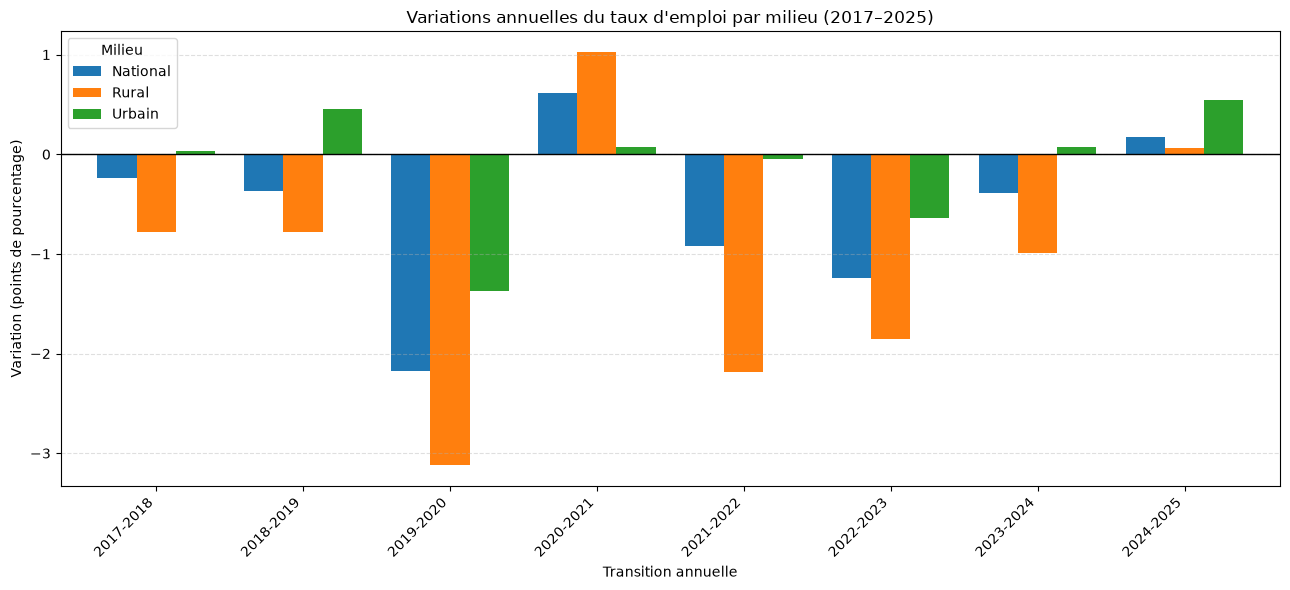

In [85]:
# Create a grouped bar chart of annual changes
ax = df_employment_annual_changes.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

# Add a horizontal reference line at zero
ax.axhline(y=0, color="black", linewidth=1)

# Add labels and title
ax.set_title("Variations annuelles du taux d'emploi par milieu (2017–2025)")
ax.set_xlabel("Transition annuelle")
ax.set_ylabel("Variation (points de pourcentage)")

# Improve readability
ax.set_xticklabels(
    df_employment_annual_changes.index,
    rotation=45,
    ha="right"
)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(title="Milieu")

plt.tight_layout()

# Save the figure
plt.savefig(
    FIGURES_DIR / "employment_annual_changes_by_milieu.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Interprétation du graphique
Voici les observations principales :
1. 2019–2020 : diminution simultanée dans les trois milieux. Le milieu rural connaît la plus forte baisse (−3,12 points).
2. 2020–2021 : reprise dans les trois milieux, particulièrement en milieu rural (+1,03 point).
3. 2021–2022 et 2022–2023 : nouvelles diminutions, surtout dans le milieu rural.
4. 2023–2024 : évolution contrastée : diminution dans les milieux National et Rural, légère augmentation en milieu Urbain.
5. 2024–2025 : augmentation dans les trois milieux.
Le graphique est également pertinent méthodologiquement : la ligne horizontale à zéro permet de distinguer immédiatement les augmentations des diminutions.

In [86]:
# Retrieve the balanced national panel
df_employment_province_evolution = balanced_panels["National"].copy()

# Calculate the change between 2017 and 2025
df_employment_province_evolution["Variation_pp"] = (
    df_employment_province_evolution[2025]
    - df_employment_province_evolution[2017]
)

# Sort provinces by their employment rate variation
df_employment_province_evolution = (
    df_employment_province_evolution
    .sort_values(by="Variation_pp", ascending=False)
)

# Display the first results
display(df_employment_province_evolution.head(10).round(2))

Annee,2017,2018,2019,2020,2021,2022,2023,2024,2025,Variation_pp
Provinces/Préfectures,,,,,,,,,,
Zagora,33.2,35.0,40.5,35.8,38.7,33.9,36.2,34.1,36.8,3.6
Chefchaouen,52.8,52.6,49.6,46.4,56.0,57.2,55.2,56.5,56.1,3.3
Larache,38.9,40.5,39.7,42.5,44.6,42.9,41.5,41.4,42.1,3.2
Fès,32.3,31.9,34.3,33.3,31.3,32.2,32.0,32.9,34.9,2.6
Tan-Tan,32.8,30.7,34.7,33.4,35.3,34.7,34.8,32.6,34.1,1.3
Tanger-Assilah,38.4,39.6,39.5,39.9,39.9,41.2,41.9,41.2,39.6,1.2
Ouarzazate,40.0,39.6,40.4,39.7,43.4,41.8,40.0,42.0,40.9,0.9
Rabat,36.7,36.9,36.7,35.7,34.3,35.2,35.0,36.8,37.4,0.7
Ouezzane,43.6,41.7,39.8,44.7,51.7,50.4,47.9,44.7,44.3,0.7


In [87]:
# Extract the provincial employment rate variations
employment_variations = df_employment_province_evolution["Variation_pp"]

# Calculate descriptive statistics
employment_variation_stats = employment_variations.agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

print("Descriptive statistics of employment rate variations:")
display(employment_variation_stats.round(2))

# Count increases, decreases and stable territories
employment_variation_distribution = pd.Series({
    "Augmentations": (employment_variations > 0).sum(),
    "Diminutions": (employment_variations < 0).sum(),
    "Stabilite": (employment_variations == 0).sum()
})

print("\nDistribution of provincial employment rate changes:")
display(employment_variation_distribution)

Descriptive statistics of employment rate variations:


count     72.00
mean      -4.55
median    -4.10
std        4.56
min      -17.40
max        3.60
Name: Variation_pp, dtype: float64


Distribution of provincial employment rate changes:


Augmentations    10
Diminutions      61
Stabilite         1
dtype: int64

In [88]:
# Identify the 10 strongest increases
top_10_employment_increases = (
    df_employment_province_evolution
    .head(10)
    [[2017, 2025, "Variation_pp"]]
)

# Identify the 10 strongest decreases
top_10_employment_decreases = (
    df_employment_province_evolution
    .tail(10)
    [[2017, 2025, "Variation_pp"]]
    .sort_values(by="Variation_pp")
)

print("Top 10 provinces with the strongest employment rate increases:")
display(top_10_employment_increases.round(2))

print("\nTop 10 provinces with the strongest employment rate decreases:")
display(top_10_employment_decreases.round(2))

Top 10 provinces with the strongest employment rate increases:


Annee,2017,2025,Variation_pp
Provinces/Préfectures,,,
Zagora,33.2,36.8,3.6
Chefchaouen,52.8,56.1,3.3
Larache,38.9,42.1,3.2
Fès,32.3,34.9,2.6
Tan-Tan,32.8,34.1,1.3
Tanger-Assilah,38.4,39.6,1.2
Ouarzazate,40.0,40.9,0.9
Rabat,36.7,37.4,0.7
Ouezzane,43.6,44.3,0.7



Top 10 provinces with the strongest employment rate decreases:


Annee,2017,2025,Variation_pp
Provinces/Préfectures,,,
Azilal,42.8,25.4,-17.4
Benslimane,57.0,40.4,-16.6
Sidi Bennour,65.3,50.1,-15.2
Taounate,53.5,39.9,-13.6
Oued Ed-Dahab,66.6,53.2,-13.4
Chichaoua,50.1,37.2,-12.9
Essaouira,54.3,42.8,-11.5
Fahs-Anjra,43.4,33.4,-10.0
El Jadida,55.1,45.3,-9.8


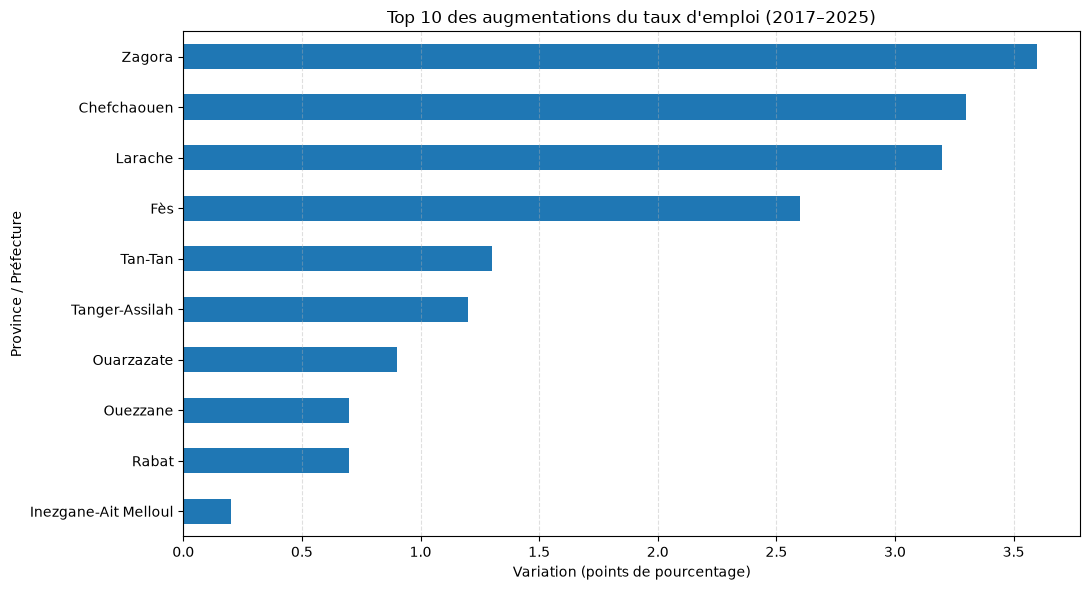

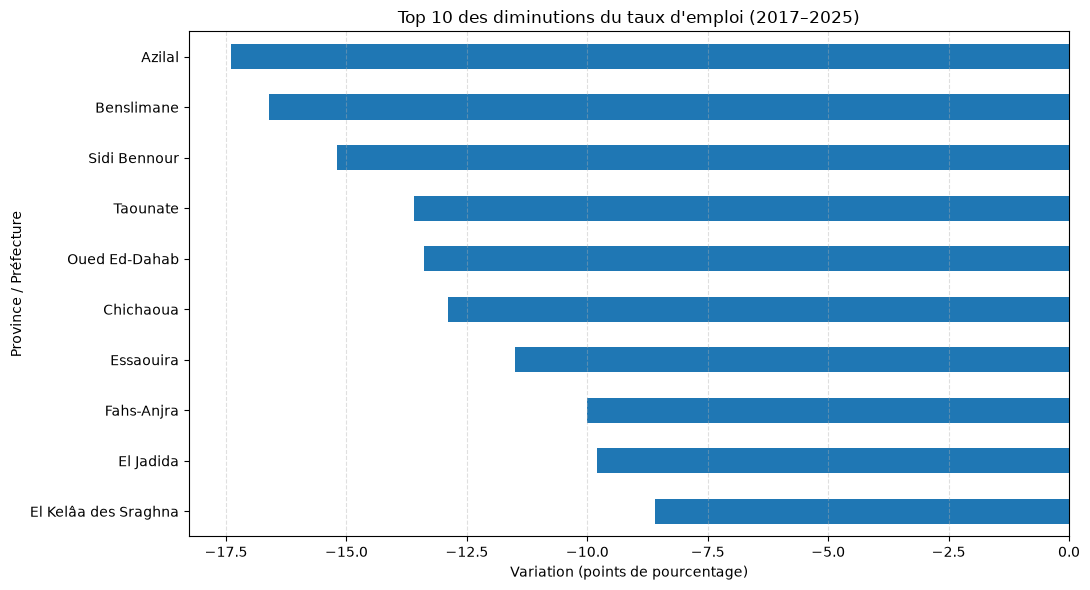

In [89]:
# Plot the 10 strongest employment rate increases
plt.figure(figsize=(11, 6))

top_10_employment_increases["Variation_pp"].sort_values().plot(
    kind="barh"
)

plt.title("Top 10 des augmentations du taux d'emploi (2017–2025)")
plt.xlabel("Variation (points de pourcentage)")
plt.ylabel("Province / Préfecture")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_10_employment_increases_2017_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Plot the 10 strongest employment rate decreases
plt.figure(figsize=(11, 6))

top_10_employment_decreases["Variation_pp"].sort_values(
    ascending=False
).plot(kind="barh")

plt.title("Top 10 des diminutions du taux d'emploi (2017–2025)")
plt.xlabel("Variation (points de pourcentage)")
plt.ylabel("Province / Préfecture")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_10_employment_decreases_2017_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

La comparaison des taux d'emploi entre 2017 et 2025, réalisée sur un panel équilibré de 72 provinces et préfectures, révèle une tendance générale à la diminution. En effet, 61 territoires (84,72 %) enregistrent une baisse de leur taux d'emploi, contre 10 (13,89 %) présentant une augmentation. Un seul territoire affiche une stabilité entre les deux années. La variation moyenne atteint −4,55 points de pourcentage et la variation médiane −4,10 points. Azilal enregistre la plus forte diminution (−17,4 points), tandis que Zagora présente la plus forte augmentation (+3,6 points). Ces résultats mettent en évidence des évolutions territoriales hétérogènes. Toutefois, la comparaison des seules années 2017 et 2025 ne permet pas de décrire les fluctuations intermédiaires. Une analyse des variations annuelles est donc nécessaire pour approfondir ces résultats.

In [90]:
# Calculate annual changes for each province/prefecture
df_employment_annual_province_changes = (
    balanced_panels["National"].diff(axis=1)
)

# Remove the first column because it contains only NaN values
df_employment_annual_province_changes = (
    df_employment_annual_province_changes.iloc[:, 1:].copy()
)

# Create readable transition labels
df_employment_annual_province_changes.columns = [
    f"{year - 1}-{year}"
    for year in balanced_panels["National"].columns[1:]
]

print("Annual provincial changes shape:",
      df_employment_annual_province_changes.shape)

print("\nMissing values:",
      df_employment_annual_province_changes.isna().sum().sum())

display(df_employment_annual_province_changes.head(10).round(2))

Annual provincial changes shape: (72, 8)

Missing values: 0


,2017-2018,2018-2019,2019-2020,2020-2021,2021-2022,2022-2023,2023-2024,2024-2025
Provinces/Préfectures,,,,,,,,
Agadir-Ida-Ou-Tanane,-1.3,1.4,-1.2,-0.6,-2.2,0.8,1.7,0.5
Al Haouz,0.3,-0.7,-3.2,1.8,-1.8,0.0,-2.6,1.1
Al Hoceima,0.3,-4.5,-3.9,5.2,2.7,-3.3,0.4,-0.4
Azilal,-1.4,2.5,-3.2,-0.2,-4.4,-6.2,-2.9,-1.6
Benslimane,-1.3,-1.4,-9.3,-0.7,-2.6,-1.8,0.3,0.2
Berkane,0.9,0.0,-3.4,1.8,0.6,-2.8,0.1,-2.5
Berrechid,0.2,1.5,-5.9,1.2,-2.1,-0.7,0.6,0.0
Boujdour,7.4,-10.5,4.0,-6.4,-1.5,2.1,3.2,-2.2
Boulemane,-0.4,2.8,-1.8,-0.6,-1.1,-3.0,0.2,0.5


In [91]:
# Count positive and negative annual changes for each territory
df_employment_trajectory = pd.DataFrame(index=(
    df_employment_annual_province_changes.index
))

df_employment_trajectory["Augmentations"] = (
    df_employment_annual_province_changes > 0
).sum(axis=1)

df_employment_trajectory["Diminutions"] = (
    df_employment_annual_province_changes < 0
).sum(axis=1)

df_employment_trajectory["Stabilite"] = (
    df_employment_annual_province_changes == 0
).sum(axis=1)

# Classify the dominant trajectory using the 6-out-of-8 rule
conditions = [
    df_employment_trajectory["Augmentations"] >= 6,
    df_employment_trajectory["Diminutions"] >= 6
]

categories = [
    "Tendance dominante à la hausse",
    "Tendance dominante à la baisse"
]

df_employment_trajectory["Trajectoire"] = np.select(
    conditions,
    categories,
    default="Evolution fluctuante"
)

# Display the number of territories in each category
print("Distribution of provincial employment trajectories:")

display(
    df_employment_trajectory["Trajectoire"]
    .value_counts()
    .to_frame("Nombre de territoires")
)

Distribution of provincial employment trajectories:


,Nombre de territoires
Trajectoire,
Evolution fluctuante,53
Tendance dominante à la baisse,19


In [92]:
# Display territories with a dominant increasing trajectory
print("Territories with a dominant increasing trajectory:")

display(
    df_employment_trajectory[
        df_employment_trajectory["Trajectoire"]
        == "Tendance dominante à la hausse"
    ].sort_values("Augmentations", ascending=False)
)

# Display territories with a dominant decreasing trajectory
print("\nTerritories with a dominant decreasing trajectory:")

display(
    df_employment_trajectory[
        df_employment_trajectory["Trajectoire"]
        == "Tendance dominante à la baisse"
    ].sort_values("Diminutions", ascending=False)
)

# Display territories with fluctuating trajectories
print("\nTerritories with fluctuating trajectories:")

display(
    df_employment_trajectory[
        df_employment_trajectory["Trajectoire"]
        == "Evolution fluctuante"
    ].sort_values("Diminutions", ascending=False)
)

Territories with a dominant increasing trajectory:


,Augmentations,Diminutions,Stabilite,Trajectoire
Provinces/Préfectures,,,,



Territories with a dominant decreasing trajectory:


,Augmentations,Diminutions,Stabilite,Trajectoire
Provinces/Préfectures,,,,
Azilal,1,7,0,Tendance dominante à la baisse
El Kelâa des Sraghna,1,7,0,Tendance dominante à la baisse
Chichaoua,1,7,0,Tendance dominante à la baisse
Essaouira,1,7,0,Tendance dominante à la baisse
Khémisset,1,7,0,Tendance dominante à la baisse
Béni Mellal,2,6,0,Tendance dominante à la baisse
Benslimane,2,6,0,Tendance dominante à la baisse
El Jadida,1,6,1,Tendance dominante à la baisse
Fquih Ben Salah,2,6,0,Tendance dominante à la baisse



Territories with fluctuating trajectories:


,Augmentations,Diminutions,Stabilite,Trajectoire
Provinces/Préfectures,,,,
Guelmim,3,5,0,Evolution fluctuante
Driouch,3,5,0,Evolution fluctuante
El Hajeb,3,5,0,Evolution fluctuante
Chefchaouen,3,5,0,Evolution fluctuante
Boulemane,3,5,0,Evolution fluctuante
Jerada,3,5,0,Evolution fluctuante
Ifrane,3,5,0,Evolution fluctuante
Figuig,3,5,0,Evolution fluctuante
Oued Ed-Dahab,3,5,0,Evolution fluctuante


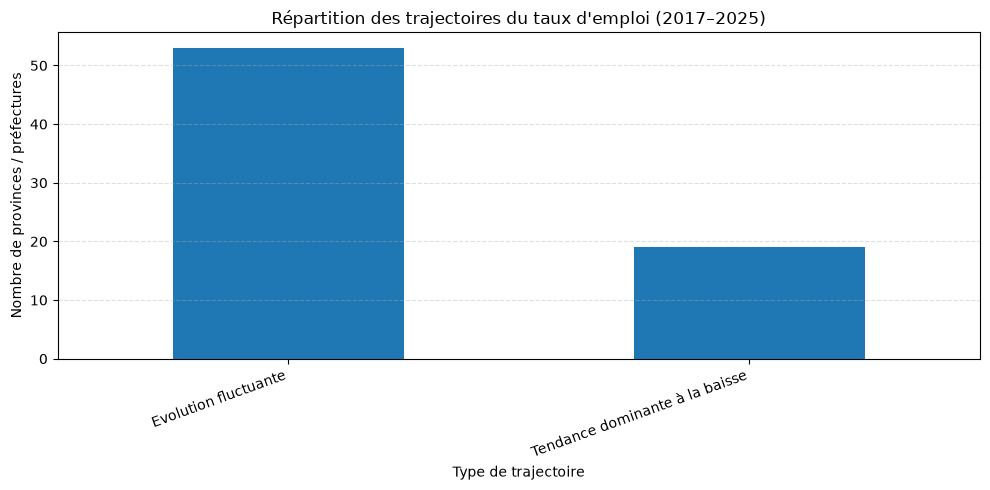

In [93]:
# Count territories in each trajectory category
trajectory_counts = (
    df_employment_trajectory["Trajectoire"]
    .value_counts()
)

# Create a bar chart
plt.figure(figsize=(10, 5))

trajectory_counts.plot(kind="bar")

plt.title("Répartition des trajectoires du taux d'emploi (2017–2025)")
plt.xlabel("Type de trajectoire")
plt.ylabel("Nombre de provinces / préfectures")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Save the figure
plt.savefig(
    FIGURES_DIR / "employment_trajectory_distribution_2017_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [94]:
# Retrieve the balanced national panel
df_employment_slopes = balanced_panels["National"].copy()

# Define the observation years
years = df_employment_slopes.columns.to_numpy(dtype=float)

# Calculate the linear trend slope for each territory
df_employment_slopes["Pente_pp_par_an"] = (
    df_employment_slopes.apply(
        lambda row: np.polyfit(
            years,
            row.to_numpy(dtype=float),
            1
        )[0],
        axis=1
    )
)

# Add the endpoint variation for comparison
df_employment_slopes["Variation_2017_2025"] = (
    df_employment_slopes[2025] - df_employment_slopes[2017]
)

# Display the descriptive statistics of the slopes
display(
    df_employment_slopes["Pente_pp_par_an"]
    .describe()
    .round(3)
)

count    72.000
mean     -0.658
std       0.639
min      -2.423
25%      -1.028
50%      -0.618
75%      -0.235
max       0.782
Name: Pente_pp_par_an, dtype: float64

In [95]:
# Identify the strongest positive linear trends
top_10_positive_slopes = (
    df_employment_slopes
    .sort_values("Pente_pp_par_an", ascending=False)
    [[2017, 2025, "Variation_2017_2025", "Pente_pp_par_an"]]
    .head(10)
)

# Identify the strongest negative linear trends
top_10_negative_slopes = (
    df_employment_slopes
    .sort_values("Pente_pp_par_an", ascending=True)
    [[2017, 2025, "Variation_2017_2025", "Pente_pp_par_an"]]
    .head(10)
)

print("Top 10 des tendances linéaires positives :")
display(top_10_positive_slopes.round(2))

print("\nTop 10 des tendances linéaires négatives :")
display(top_10_negative_slopes.round(2))

# Count positive, negative and zero slopes
slope_distribution = pd.Series({
    "Pentes positives": (
        df_employment_slopes["Pente_pp_par_an"] > 0
    ).sum(),
    "Pentes négatives": (
        df_employment_slopes["Pente_pp_par_an"] < 0
    ).sum(),
    "Pentes nulles": (
        df_employment_slopes["Pente_pp_par_an"] == 0
    ).sum()
})

print("\nDistribution of linear trend slopes:")
display(slope_distribution)

Top 10 des tendances linéaires positives :


Annee,2017,2025,Variation_2017_2025,Pente_pp_par_an
Provinces/Préfectures,,,,
Chefchaouen,52.8,56.1,3.3,0.78
Ouezzane,43.6,44.3,0.7,0.56
Larache,38.9,42.1,3.2,0.33
Tanger-Assilah,38.4,39.6,1.2,0.26
Tan-Tan,32.8,34.1,1.3,0.21
Ouarzazate,40.0,40.9,0.9,0.20
Ifrane,44.7,44.7,0.0,0.14
Fès,32.3,34.9,2.6,0.13
El Hajeb,39.9,39.1,-0.8,0.07



Top 10 des tendances linéaires négatives :


Annee,2017,2025,Variation_2017_2025,Pente_pp_par_an
Provinces/Préfectures,,,,
Azilal,42.8,25.4,-17.4,-2.42
Benslimane,57.0,40.4,-16.6,-2.42
Sidi Bennour,65.3,50.1,-15.2,-2.13
Chichaoua,50.1,37.2,-12.9,-1.89
Essaouira,54.3,42.8,-11.5,-1.60
Taounate,53.5,39.9,-13.6,-1.56
Oued Ed-Dahab,66.6,53.2,-13.4,-1.54
Settat,50.1,41.7,-8.4,-1.45
El Jadida,55.1,45.3,-9.8,-1.31



Distribution of linear trend slopes:


Pentes positives    10
Pentes négatives    62
Pentes nulles        0
dtype: int64

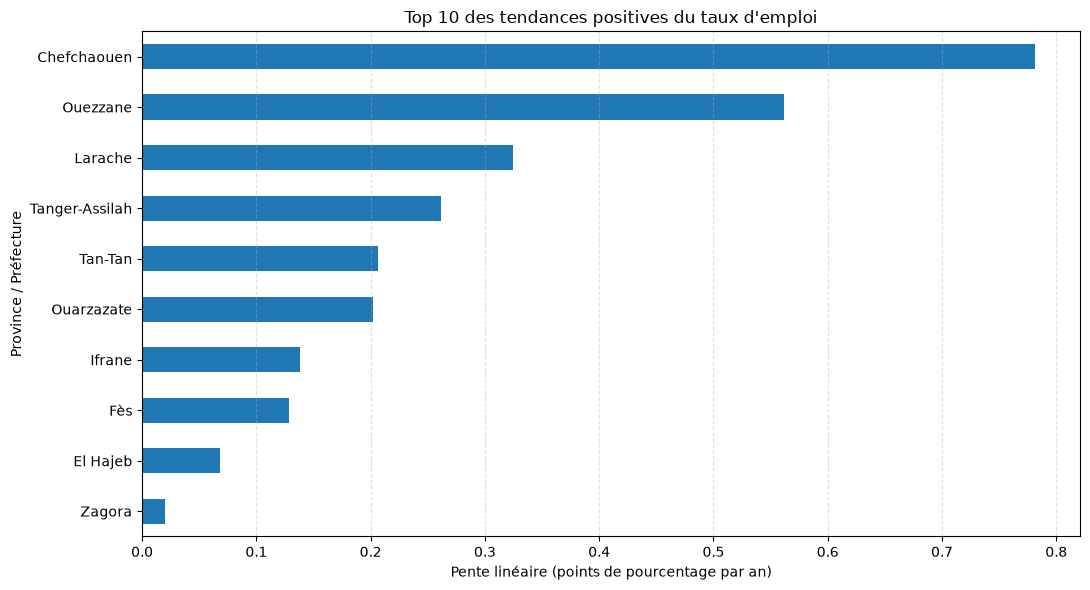

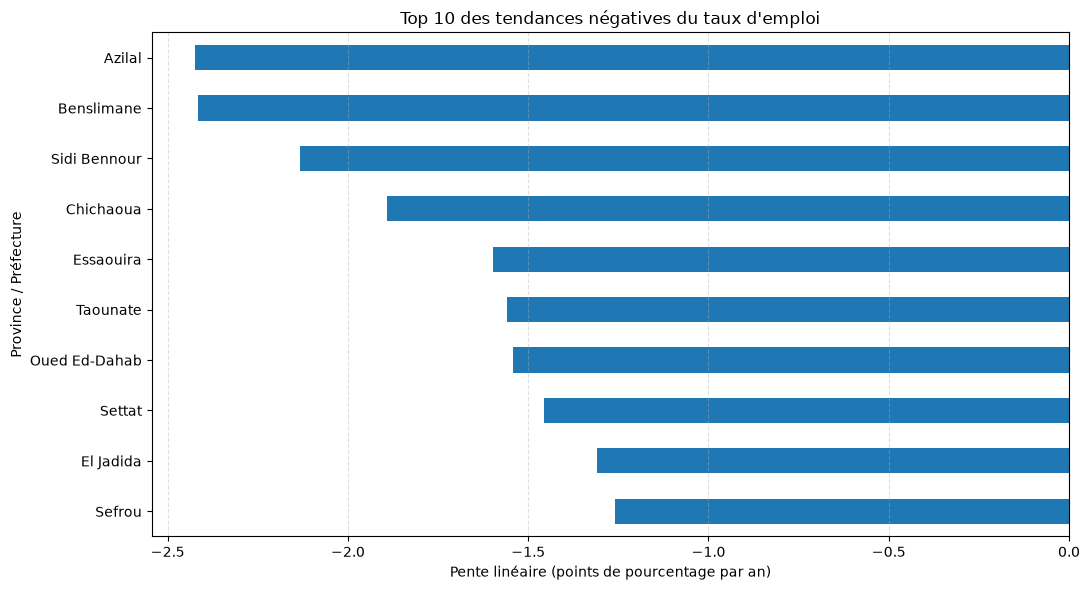

In [96]:
# Prepare the 10 strongest positive and negative slopes
positive_slope_data = (
    df_employment_slopes
    .nlargest(10, "Pente_pp_par_an")
    .sort_values("Pente_pp_par_an")
)

negative_slope_data = (
    df_employment_slopes
    .nsmallest(10, "Pente_pp_par_an")
    .sort_values("Pente_pp_par_an", ascending=False)
)

# Plot the strongest positive slopes
plt.figure(figsize=(11, 6))

positive_slope_data["Pente_pp_par_an"].plot(kind="barh")

plt.title("Top 10 des tendances positives du taux d'emploi")
plt.xlabel("Pente linéaire (points de pourcentage par an)")
plt.ylabel("Province / Préfecture")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_10_positive_employment_slopes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Plot the strongest negative slopes
plt.figure(figsize=(11, 6))

negative_slope_data["Pente_pp_par_an"].plot(kind="barh")

plt.title("Top 10 des tendances négatives du taux d'emploi")
plt.xlabel("Pente linéaire (points de pourcentage par an)")
plt.ylabel("Province / Préfecture")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_10_negative_employment_slopes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Pearson correlation: 0.944
Spearman correlation: 0.926


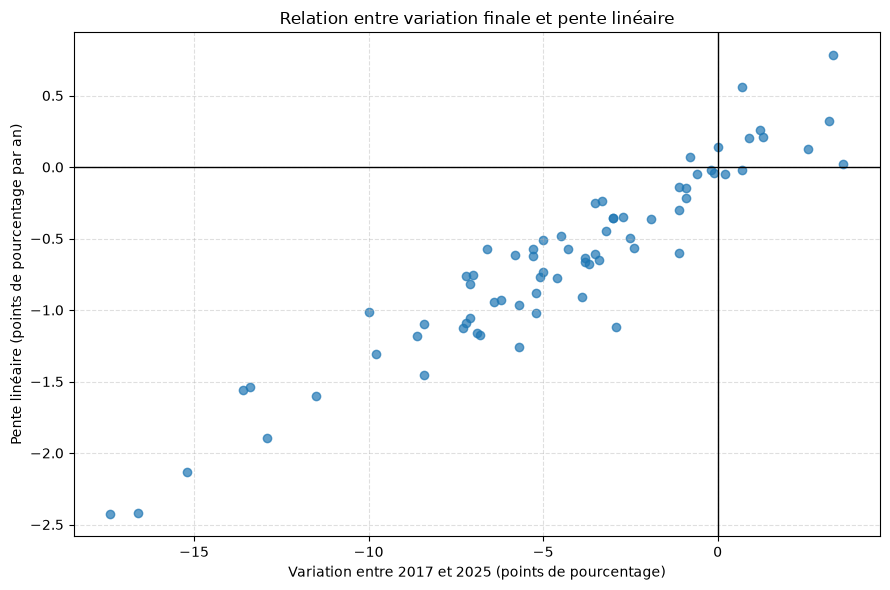

In [97]:
# Calculate Pearson and Spearman correlations
pearson_corr = df_employment_slopes[
    ["Variation_2017_2025", "Pente_pp_par_an"]
].corr(method="pearson").iloc[0, 1]

spearman_corr = df_employment_slopes[
    ["Variation_2017_2025", "Pente_pp_par_an"]
].corr(method="spearman").iloc[0, 1]

print(f"Pearson correlation: {pearson_corr:.3f}")
print(f"Spearman correlation: {spearman_corr:.3f}")

# Create a scatter plot
plt.figure(figsize=(9, 6))

plt.scatter(
    df_employment_slopes["Variation_2017_2025"],
    df_employment_slopes["Pente_pp_par_an"],
    alpha=0.7
)

plt.axhline(y=0, color="black", linewidth=1)
plt.axvline(x=0, color="black", linewidth=1)

plt.title("Relation entre variation finale et pente linéaire")
plt.xlabel("Variation entre 2017 et 2025 (points de pourcentage)")
plt.ylabel("Pente linéaire (points de pourcentage par an)")

plt.grid(linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "employment_variation_vs_slope.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [98]:
# Identify territories with opposite endpoint and slope directions
opposite_trends = df_employment_slopes[
    (
        (df_employment_slopes["Variation_2017_2025"] > 0)
        & (df_employment_slopes["Pente_pp_par_an"] < 0)
    )
    |
    (
        (df_employment_slopes["Variation_2017_2025"] < 0)
        & (df_employment_slopes["Pente_pp_par_an"] > 0)
    )
].copy()

# Sort by absolute difference in direction
opposite_trends["Ecart_indicateurs"] = (
    opposite_trends["Variation_2017_2025"]
    - opposite_trends["Pente_pp_par_an"] * 8
)

print("Number of territories with opposite directions:",
      len(opposite_trends))

display(
    opposite_trends[
        [2017, 2025, "Variation_2017_2025",
         "Pente_pp_par_an", "Ecart_indicateurs"]
    ].round(2)
)

Number of territories with opposite directions: 3


Annee,2017,2025,Variation_2017_2025,Pente_pp_par_an,Ecart_indicateurs
Provinces/Préfectures,,,,,
El Hajeb,39.9,39.1,-0.8,0.07,-1.35
Inezgane-Ait Melloul,36.8,37.0,0.2,-0.05,0.59
Rabat,36.7,37.4,0.7,-0.02,0.89


In [99]:
# Combine the main territorial analysis results
df_employment_final_territory = (
    df_employment_slopes[
        [2017, 2025, "Variation_2017_2025", "Pente_pp_par_an"]
    ]
    .join(
        df_employment_trajectory[
            ["Augmentations", "Diminutions", "Stabilite", "Trajectoire"]
        ]
    )
    .copy()
)

# Set the index name
df_employment_final_territory.index.name = "Provinces/Préfectures"

# Round numerical indicators for readability
numeric_cols = [
    2017, 2025,
    "Variation_2017_2025",
    "Pente_pp_par_an"
]

df_employment_final_territory[numeric_cols] = (
    df_employment_final_territory[numeric_cols].round(2)
)

# Export the consolidated territorial analysis
output_path = (
    PROCESSED_DIR / "i_imt_txemp_02_territorial_analysis.csv"
)

df_employment_final_territory.to_csv(
    output_path,
    encoding="utf-8-sig"
)

print("Final territorial dataset shape:",
      df_employment_final_territory.shape)

print("\nExported file:", output_path)

display(df_employment_final_territory.head(10))

Final territorial dataset shape: (72, 8)

Exported file: c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\data\processed\i_imt_txemp_02_territorial_analysis.csv


,2017,2025,Variation_2017_2025,Pente_pp_par_an,Augmentations,Diminutions,Stabilite,Trajectoire
Provinces/Préfectures,,,,,,,,
Agadir-Ida-Ou-Tanane,36.2,35.3,-0.9,-0.22,4,4,0,Evolution fluctuante
Al Haouz,47.3,42.2,-5.1,-0.77,3,4,1,Evolution fluctuante
Al Hoceima,48.3,44.8,-3.5,-0.25,4,4,0,Evolution fluctuante
Azilal,42.8,25.4,-17.4,-2.42,1,7,0,Tendance dominante à la baisse
Benslimane,57.0,40.4,-16.6,-2.42,2,6,0,Tendance dominante à la baisse
Berkane,36.8,31.5,-5.3,-0.62,4,3,1,Evolution fluctuante
Berrechid,46.6,41.4,-5.2,-0.88,4,3,1,Evolution fluctuante
Boujdour,42.8,38.9,-3.9,-0.91,4,4,0,Evolution fluctuante
Boulemane,36.7,33.3,-3.4,-0.65,3,5,0,Evolution fluctuante


In [100]:
# Classify the direction of the endpoint variation
df_direction_comparison = pd.DataFrame(
    index=df_employment_slopes.index
)

df_direction_comparison["Variation_finale"] = np.select(
    [
        df_employment_slopes["Variation_2017_2025"] > 0,
        df_employment_slopes["Variation_2017_2025"] < 0
    ],
    ["Hausse", "Baisse"],
    default="Stable"
)

# Classify the direction of the linear slope
df_direction_comparison["Pente_lineaire"] = np.select(
    [
        df_employment_slopes["Pente_pp_par_an"] > 0,
        df_employment_slopes["Pente_pp_par_an"] < 0
    ],
    ["Hausse", "Baisse"],
    default="Stable"
)

# Create a comparison table
direction_comparison = pd.crosstab(
    df_direction_comparison["Variation_finale"],
    df_direction_comparison["Pente_lineaire"],
    margins=True
)

print("Comparison between endpoint variation and linear slope:")
display(direction_comparison)

# Count territories with matching and opposite directions
same_direction = (
    df_direction_comparison["Variation_finale"]
    == df_direction_comparison["Pente_lineaire"]
).sum()

opposite_direction = (
    df_direction_comparison["Variation_finale"]
    != df_direction_comparison["Pente_lineaire"]
).sum()

print("\nSame direction:", same_direction)
print("Different direction:", opposite_direction)

Comparison between endpoint variation and linear slope:


Pente_lineaire,Baisse,Hausse,All
Variation_finale,,,
Baisse,60,1,61
Hausse,2,8,10
Stable,0,1,1
All,62,10,72



Same direction: 68
Different direction: 4


In [101]:
# Check the final territorial dataset
print("Final dataset validation")

print("\nShape:")
print(df_employment_final_territory.shape)

print("\nMissing values:")
print(df_employment_final_territory.isna().sum())

print("\nDuplicate territories:",
      df_employment_final_territory.index.duplicated().sum())

print("\nTrajectory distribution:")
display(
    df_employment_final_territory["Trajectoire"]
    .value_counts()
    .to_frame("Nombre")
)

print("\nAnnual transition counts:")
print(
    df_employment_final_territory[
        ["Augmentations", "Diminutions", "Stabilite"]
    ].sum(axis=1).value_counts()
)

Final dataset validation

Shape:
(72, 8)

Missing values:
2017                   0
2025                   0
Variation_2017_2025    0
Pente_pp_par_an        0
Augmentations          0
Diminutions            0
Stabilite              0
Trajectoire            0
dtype: int64

Duplicate territories: 0

Trajectory distribution:


,Nombre
Trajectoire,
Evolution fluctuante,53
Tendance dominante à la baisse,19



Annual transition counts:
8    72
Name: count, dtype: int64


## Synthèse de l'analyse territoriale du taux d'emploi
L'analyse des taux d'emploi par province et préfecture sur la période 2017–2025 met en évidence une évolution globalement défavorable dans les territoires étudiés. Sur les 72 territoires disposant de données complètes pour les neuf années, 61 enregistrent une diminution de leur taux d'emploi entre 2017 et 2025, contre 10 augmentations et une situation stable.

La variation moyenne atteint −4,55 points de pourcentage, tandis que la variation médiane s'établit à −4,10 points. Les diminutions les plus importantes concernent notamment Azilal (−17,4 points), Benslimane (−16,6 points) et Sidi Bennour (−15,2 points).

L'étude des huit transitions annuelles montre cependant que les trajectoires ne sont pas toutes régulières. Selon la règle de classification retenue, 19 territoires présentent une tendance dominante à la baisse, tandis que 53 présentent une évolution fluctuante. Aucun territoire ne satisfait le critère d'une tendance dominante à la hausse.

L'analyse des tendances linéaires complète ces observations : 62 territoires présentent une pente négative et 10 une pente positive. La corrélation entre la variation finale et la pente linéaire est élevée (Pearson : 0,944 ; Spearman : 0,926), ce qui indique une forte association entre les deux mesures.

Ces résultats doivent être interprétés en tenant compte de plusieurs limites. Le panel équilibré ne comprend que 72 des 74 territoires du dataset national, car deux territoires présentent des données manquantes. Les moyennes territoriales sont non pondérées et ne représentent pas directement les taux agrégés de la population marocaine. Enfin, cette analyse descriptive ne permet pas d'identifier les causes des évolutions observées.

In [102]:
# Load the original metadata workbooks
employment_metadata_raw = pd.read_excel(
    RAW_DIR / "i_imt_txemp_02_metadata.xlsx",
    sheet_name="Metadata",
    header=None
)

unemployment_metadata_raw = pd.read_excel(
    RAW_DIR / "i_imt_txch_02_metadata.xlsx",
    sheet_name="Metadata",
    header=None
)

print("EMPLOYMENT DATASET — ORIGINAL METADATA")
display(employment_metadata_raw.head(15))

print("\nUNEMPLOYMENT DATASET — ORIGINAL METADATA")
display(unemployment_metadata_raw.head(15))

EMPLOYMENT DATASET — ORIGINAL METADATA


c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,0,1
0,L'indicateur,Taux d'emploi selon les Provinces/Préfectures ...
1,Définition,Taux d'emploi selon les Provinces/Préfectures ...
2,Périodicité,Annuelle
3,Unité,POURCENTAGE
4,Source,MAR_HCP ENQUETE NATIONALE SUR L'EMPLOI



UNEMPLOYMENT DATASET — ORIGINAL METADATA


,0,1
0,L'indicateur,Taux de chômage selon les Provinces/Préfecture...
1,Définition,Taux de chômage selon les Provinces/Préfecture...
2,Périodicité,Annuelle
3,Unité,POURCENTAGE
4,Source,MAR_HCP ENQUETE NATIONALE SUR L'EMPLOI


In [103]:
# Display the complete metadata values
print("EMPLOYMENT INDICATOR")
print("Indicator:", employment_metadata_raw.iloc[0, 1])
print("Definition:", employment_metadata_raw.iloc[1, 1])

print("\nUNEMPLOYMENT INDICATOR")
print("Indicator:", unemployment_metadata_raw.iloc[0, 1])
print("Definition:", unemployment_metadata_raw.iloc[1, 1])

EMPLOYMENT INDICATOR
Indicator: Taux d'emploi selon les Provinces/Préfectures et le Milieu
Definition: Taux d'emploi selon les Provinces/Préfectures et le Milieu

UNEMPLOYMENT INDICATOR
Indicator: Taux de chômage selon les Provinces/Préfectures et le Milieu
Definition: Taux de chômage selon les Provinces/Préfectures et le Milieu


In [106]:
# Load the previously cleaned unemployment dataset
df_unemployment_clean = pd.read_csv(
    PROCESSED_DIR / "i_imt_txch_02_cleaned.csv"
)

# Verify the imported dataset
print("Unemployment dataset shape:", df_unemployment_clean.shape)

display(df_unemployment_clean.head())

Unemployment dataset shape: (179, 11)


,Milieu,Provinces/Préfectures,2025,2024,2023,2022,2021,2020,2019,2018,2017
0,National,Al Hoceima,6.7,8.0,10.2,8.5,10.0,11.4,8.4,7.0,7.8
1,National,Chefchaouen,4.6,6.0,6.0,5.0,4.6,5.5,4.7,3.8,3.9
2,National,Larache,8.7,9.1,10.1,9.6,9.2,9.2,6.5,6.5,9.1
3,National,Ouezzane,7.4,6.4,4.9,4.3,5.5,4.5,8.4,7.2,7.2
4,National,Tanger-Assilah,10.9,12.1,10.5,12.4,12.9,11.0,8.9,7.4,8.4


In [107]:
# Extract unique territories from both datasets
employment_territories = set(
    df_employment_clean.loc[
        df_employment_clean["Milieu"] == "National",
        "Provinces/Préfectures"
    ].dropna()
)

unemployment_territories = set(
    df_unemployment_clean.loc[
        df_unemployment_clean["Milieu"] == "National",
        "Provinces/Préfectures"
    ].dropna()
)

# Identify common and dataset-specific territories
common_territories = sorted(
    employment_territories & unemployment_territories
)

employment_only = sorted(
    employment_territories - unemployment_territories
)

unemployment_only = sorted(
    unemployment_territories - employment_territories
)

# Display comparison results
print("Employment territories:", len(employment_territories))
print("Unemployment territories:", len(unemployment_territories))
print("Common territories:", len(common_territories))

print("\nEmployment-only territories:")
print(employment_only)

print("\nUnemployment-only territories:")
print(unemployment_only)

Employment territories: 74
Unemployment territories: 71
Common territories: 71

Employment-only territories:
['Assa-Zag', 'Fahs-Anjra', 'Tarfaya']

Unemployment-only territories:
[]


In [108]:
# Define the common analysis period
year_cols = [str(year) for year in range(2017, 2026)]

# Keep only the National observations for common territories
employment_common = (
    df_employment_clean[
        (df_employment_clean["Milieu"] == "National")
        & (df_employment_clean["Provinces/Préfectures"].isin(common_territories))
    ]
    .set_index("Provinces/Préfectures")
    .reindex(common_territories)
)

unemployment_common = (
    df_unemployment_clean[
        (df_unemployment_clean["Milieu"] == "National")
        & (df_unemployment_clean["Provinces/Préfectures"].isin(common_territories))
    ]
    .set_index("Provinces/Préfectures")
    .reindex(common_territories)
)

# Compare annual data availability
coverage_records = []

for year in year_cols:
    employment_available = employment_common[year].notna()
    unemployment_available = unemployment_common[year].notna()

    both_available = employment_available & unemployment_available

    coverage_records.append({
        "Annee": year,
        "Emploi_disponible": employment_available.sum(),
        "Chomage_disponible": unemployment_available.sum(),
        "Deux_indicateurs_disponibles": both_available.sum(),
        "Territoires_incomplets": (~both_available).sum()
    })

df_coverage_comparison = pd.DataFrame(coverage_records)

display(df_coverage_comparison)

,Annee,Emploi_disponible,Chomage_disponible,Deux_indicateurs_disponibles,Territoires_incomplets
0,2017,71,67,67,4
1,2018,71,64,64,7
2,2019,71,67,67,4
3,2020,71,67,67,4
4,2021,71,68,68,3
5,2022,71,70,70,1
6,2023,71,70,70,1
7,2024,71,71,71,0
8,2025,71,70,70,1


In [109]:
# Count missing values for each territory across the nine years
employment_missing = employment_common[year_cols].isna().sum(axis=1)
unemployment_missing = unemployment_common[year_cols].isna().sum(axis=1)

# Identify territories with complete data in both datasets
complete_both = (
    (employment_missing == 0)
    & (unemployment_missing == 0)
)

# Build a territorial availability summary
df_territory_coverage = pd.DataFrame({
    "Emploi_valeurs_manquantes": employment_missing,
    "Chomage_valeurs_manquantes": unemployment_missing,
    "Complet_dans_les_deux": complete_both
})

print("Total common territories:", len(common_territories))
print("Territories complete in both datasets:", complete_both.sum())
print("Territories incomplete in at least one dataset:", (~complete_both).sum())

print("\nTerritories with incomplete data:")
display(df_territory_coverage[~df_territory_coverage["Complet_dans_les_deux"]])

print("\nNumber of missing values per dataset:")
print("Employment:", employment_missing.sum())
print("Unemployment:", unemployment_missing.sum())

Total common territories: 71
Territories complete in both datasets: 62
Territories incomplete in at least one dataset: 9

Territories with incomplete data:


,Emploi_valeurs_manquantes,Chomage_valeurs_manquantes,Complet_dans_les_deux
Provinces/Préfectures,,,
Boujdour,0,4,False
Boulemane,0,3,False
Chichaoua,0,2,False
Es-Semara,0,6,False
Essaouira,0,1,False
Moulay Yacoub,0,5,False
Médiouna,0,1,False
Tata,0,2,False
Zagora,0,1,False



Number of missing values per dataset:
Employment: 0
Unemployment: 25


In [110]:
# Identify territories with complete observations in both datasets
complete_territories = sorted(
    df_territory_coverage.index[
        df_territory_coverage["Complet_dans_les_deux"]
    ].tolist()
)

# Create balanced employment and unemployment panels
employment_balanced = (
    employment_common.loc[complete_territories, year_cols]
    .copy()
)

unemployment_balanced = (
    unemployment_common.loc[complete_territories, year_cols]
    .copy()
)

# Display panel dimensions and missing values
print("Balanced employment panel:", employment_balanced.shape)
print("Balanced unemployment panel:", unemployment_balanced.shape)

print("\nMissing values in employment panel:",
      employment_balanced.isna().sum().sum())

print("Missing values in unemployment panel:",
      unemployment_balanced.isna().sum().sum())

print("\nNumber of territories:", len(complete_territories))
print("Analysis period:", year_cols[0], "-", year_cols[-1])

Balanced employment panel: (62, 9)
Balanced unemployment panel: (62, 9)

Missing values in employment panel: 0
Missing values in unemployment panel: 0

Number of territories: 62
Analysis period: 2017 - 2025


In [111]:
# Convert employment panel from wide to long format
df_employment_balanced_long = (
    employment_balanced
    .reset_index()
    .melt(
        id_vars="Provinces/Préfectures",
        var_name="Annee",
        value_name="Taux_emploi"
    )
)

# Convert unemployment panel from wide to long format
df_unemployment_balanced_long = (
    unemployment_balanced
    .reset_index()
    .melt(
        id_vars="Provinces/Préfectures",
        var_name="Annee",
        value_name="Taux_chomage"
    )
)

# Convert year labels to integers
df_employment_balanced_long["Annee"] = (
    df_employment_balanced_long["Annee"].astype(int)
)

df_unemployment_balanced_long["Annee"] = (
    df_unemployment_balanced_long["Annee"].astype(int)
)

# Combine both indicators using territory and year
df_comparison = pd.merge(
    df_employment_balanced_long,
    df_unemployment_balanced_long,
    on=["Provinces/Préfectures", "Annee"],
    how="inner",
    validate="one_to_one"
)

# Sort the resulting dataset
df_comparison = df_comparison.sort_values(
    ["Provinces/Préfectures", "Annee"]
).reset_index(drop=True)

print("Combined dataset shape:", df_comparison.shape)
display(df_comparison.head(10))

Combined dataset shape: (558, 4)


,Provinces/Préfectures,Annee,Taux_emploi,Taux_chomage
0,Agadir-Ida-Ou-Tanane,2017,36.2,13.5
1,Agadir-Ida-Ou-Tanane,2018,34.9,14.2
2,Agadir-Ida-Ou-Tanane,2019,36.3,13.3
3,Agadir-Ida-Ou-Tanane,2020,35.1,15.4
4,Agadir-Ida-Ou-Tanane,2021,34.5,15.5
5,Agadir-Ida-Ou-Tanane,2022,32.3,15.8
6,Agadir-Ida-Ou-Tanane,2023,33.1,15.9
7,Agadir-Ida-Ou-Tanane,2024,34.8,16.4
8,Agadir-Ida-Ou-Tanane,2025,35.3,14.6
9,Al Haouz,2017,47.3,3.5


In [112]:
# Check the structure of the combined dataset
print("Dataset shape:", df_comparison.shape)

print("\nColumn data types:")
print(df_comparison.dtypes)

# Check missing values
print("\nMissing values:")
print(df_comparison.isna().sum())

# Check duplicate territory-year combinations
duplicate_count = df_comparison.duplicated(
    subset=["Provinces/Préfectures", "Annee"]
).sum()

print("\nDuplicate territory-year combinations:", duplicate_count)

# Check the number of unique territories and years
print("\nUnique territories:",
      df_comparison["Provinces/Préfectures"].nunique())

print("Unique years:", sorted(df_comparison["Annee"].unique()))

# Check the number of observations per year
print("\nObservations per year:")
display(df_comparison.groupby("Annee").size().rename("Nombre_observations"))

# Display descriptive statistics for both indicators
print("\nDescriptive statistics:")
display(
    df_comparison[["Taux_emploi", "Taux_chomage"]].describe().round(2)
)

Dataset shape: (558, 4)

Column data types:
Provinces/Préfectures        str
Annee                      int64
Taux_emploi              float64
Taux_chomage             float64
dtype: object

Missing values:
Provinces/Préfectures    0
Annee                    0
Taux_emploi              0
Taux_chomage             0
dtype: int64

Duplicate territory-year combinations: 0

Unique territories: 62
Unique years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Observations per year:


Annee
2017    62
2018    62
2019    62
2020    62
2021    62
2022    62
2023    62
2024    62
2025    62
Name: Nombre_observations, dtype: int64


Descriptive statistics:


,Taux_emploi,Taux_chomage
count,558.00,558.00
mean,39.85,11.63
std,6.27,5.54
min,25.40,1.50
25%,35.42,7.50
50%,39.60,10.90
75%,43.08,14.78
max,66.60,35.50


In [113]:
# Export the validated comparison dataset
comparison_output_path = (
    PROCESSED_DIR / "employment_unemployment_comparison_balanced.csv"
)

df_comparison.to_csv(
    comparison_output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Comparison dataset exported successfully.")
print("File:", comparison_output_path)
print("Shape:", df_comparison.shape)

Comparison dataset exported successfully.
File: c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\data\processed\employment_unemployment_comparison_balanced.csv
Shape: (558, 4)


In [114]:
# Calculate annual descriptive statistics for both indicators
df_annual_comparison = (
    df_comparison
    .groupby("Annee")
    .agg(
        Taux_emploi_moyen=("Taux_emploi", "mean"),
        Taux_emploi_median=("Taux_emploi", "median"),
        Ecart_type_emploi=("Taux_emploi", "std"),
        Taux_chomage_moyen=("Taux_chomage", "mean"),
        Taux_chomage_median=("Taux_chomage", "median"),
        Ecart_type_chomage=("Taux_chomage", "std")
    )
    .reset_index()
)

# Round results for readability
df_annual_comparison = df_annual_comparison.round(2)

display(df_annual_comparison)

,Annee,Taux_emploi_moyen,Taux_emploi_median,Ecart_type_emploi,Taux_chomage_moyen,Taux_chomage_median,Ecart_type_chomage
0,2017,42.36,41.65,7.02,10.30,9.25,5.00
1,2018,41.87,41.10,6.90,9.75,8.40,5.04
2,2019,41.73,41.35,6.15,9.21,8.35,4.61
3,2020,39.30,39.30,5.33,12.22,10.90,5.81
4,2021,40.18,39.80,5.72,11.95,10.35,5.54
5,2022,39.49,39.30,6.06,11.65,10.85,5.43
6,2023,38.12,37.95,5.86,13.08,12.20,5.40
7,2024,37.72,37.85,5.77,13.40,12.20,5.51
8,2025,37.89,38.05,5.66,13.11,11.70,5.98


In [115]:
# Extract the annual mean values for 2017 and 2025
initial_values = df_annual_comparison.set_index("Annee").loc[2017]
final_values = df_annual_comparison.set_index("Annee").loc[2025]

# Calculate changes in percentage points
df_period_evolution = pd.DataFrame({
    "Indicateur": ["Taux d'emploi", "Taux de chômage"],
    "Valeur_2017": [
        initial_values["Taux_emploi_moyen"],
        initial_values["Taux_chomage_moyen"]
    ],
    "Valeur_2025": [
        final_values["Taux_emploi_moyen"],
        final_values["Taux_chomage_moyen"]
    ]
})

df_period_evolution["Variation_pp"] = (
    df_period_evolution["Valeur_2025"]
    - df_period_evolution["Valeur_2017"]
)

display(df_period_evolution.round(2))

,Indicateur,Valeur_2017,Valeur_2025,Variation_pp
0,Taux d'emploi,42.36,37.89,-4.47
1,Taux de chômage,10.30,13.11,2.81


In [116]:
# Calculate Pearson and Spearman correlations
pearson_global = df_comparison["Taux_emploi"].corr(
    df_comparison["Taux_chomage"],
    method="pearson"
)

spearman_global = df_comparison["Taux_emploi"].corr(
    df_comparison["Taux_chomage"],
    method="spearman"
)

print("GLOBAL CORRELATION — 558 OBSERVATIONS")
print(f"Pearson correlation: {pearson_global:.4f}")
print(f"Spearman correlation: {spearman_global:.4f}")

GLOBAL CORRELATION — 558 OBSERVATIONS
Pearson correlation: -0.6841
Spearman correlation: -0.7418


In [117]:
# Calculate correlations separately for each year
annual_correlations = (
    df_comparison
    .groupby("Annee")
    .apply(
        lambda group: pd.Series({
            "Pearson": group["Taux_emploi"].corr(
                group["Taux_chomage"],
                method="pearson"
            ),
            "Spearman": group["Taux_emploi"].corr(
                group["Taux_chomage"],
                method="spearman"
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(annual_correlations.round(4))

,Annee,Pearson,Spearman
0,2017,-0.6308,-0.7414
1,2018,-0.6558,-0.7308
2,2019,-0.6725,-0.7427
3,2020,-0.7602,-0.7944
4,2021,-0.7392,-0.7624
5,2022,-0.6686,-0.7091
6,2023,-0.7142,-0.7609
7,2024,-0.6073,-0.6565
8,2025,-0.6055,-0.6323


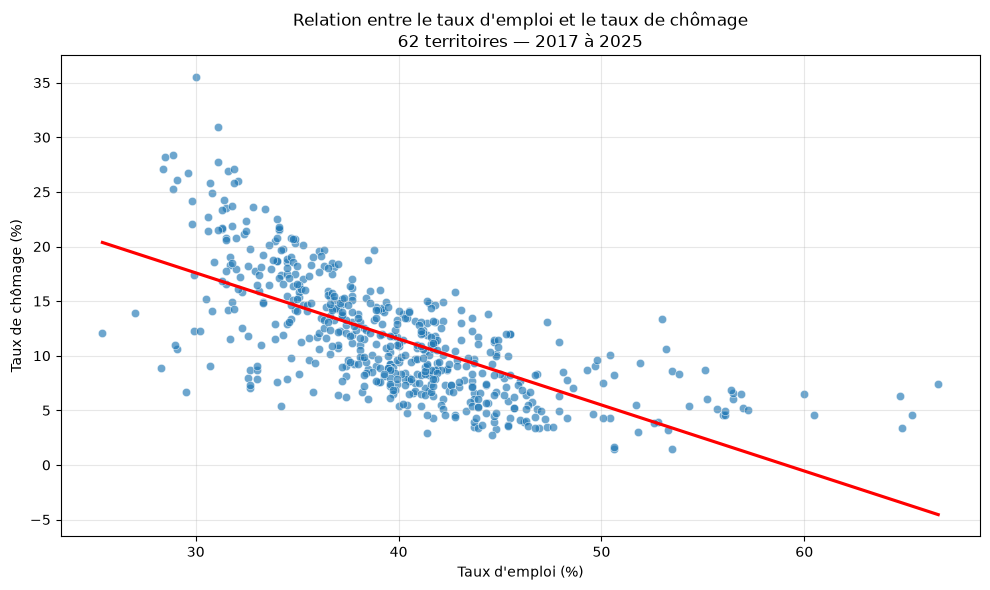

In [118]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_comparison,
    x="Taux_emploi",
    y="Taux_chomage",
    alpha=0.65
)

# Add a linear trend line for visual exploration
sns.regplot(
    data=df_comparison,
    x="Taux_emploi",
    y="Taux_chomage",
    scatter=False,
    ci=None,
    color="red"
)

plt.title(
    "Relation entre le taux d'emploi et le taux de chômage\n"
    "62 territoires — 2017 à 2025"
)
plt.xlabel("Taux d'emploi (%)")
plt.ylabel("Taux de chômage (%)")
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the figure
plt.savefig(
    FIGURES_DIR / "employment_unemployment_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [119]:
# Ensure observations are ordered by territory and year
df_comparison = df_comparison.sort_values(
    ["Provinces/Préfectures", "Annee"]
).reset_index(drop=True)

# Calculate annual changes within each territory
df_changes = df_comparison.copy()

df_changes["Variation_emploi_pp"] = (
    df_changes.groupby("Provinces/Préfectures")["Taux_emploi"]
    .diff()
)

df_changes["Variation_chomage_pp"] = (
    df_changes.groupby("Provinces/Préfectures")["Taux_chomage"]
    .diff()
)

# Remove the first year for each territory because it has no previous year
df_changes = df_changes.dropna(
    subset=["Variation_emploi_pp", "Variation_chomage_pp"]
).reset_index(drop=True)

print("Annual changes dataset shape:", df_changes.shape)

print("\nMissing values:")
display(
    df_changes[
        ["Variation_emploi_pp", "Variation_chomage_pp"]
    ].isna().sum()
)

print("\nPreview:")
display(df_changes.head(10))

Annual changes dataset shape: (496, 6)

Missing values:


Variation_emploi_pp     0
Variation_chomage_pp    0
dtype: int64


Preview:


,Provinces/Préfectures,Annee,Taux_emploi,Taux_chomage,Variation_emploi_pp,Variation_chomage_pp
0,Agadir-Ida-Ou-Tanane,2018,34.9,14.2,-1.3,0.7
1,Agadir-Ida-Ou-Tanane,2019,36.3,13.3,1.4,-0.9
2,Agadir-Ida-Ou-Tanane,2020,35.1,15.4,-1.2,2.1
3,Agadir-Ida-Ou-Tanane,2021,34.5,15.5,-0.6,0.1
4,Agadir-Ida-Ou-Tanane,2022,32.3,15.8,-2.2,0.3
5,Agadir-Ida-Ou-Tanane,2023,33.1,15.9,0.8,0.1
6,Agadir-Ida-Ou-Tanane,2024,34.8,16.4,1.7,0.5
7,Agadir-Ida-Ou-Tanane,2025,35.3,14.6,0.5,-1.8
8,Al Haouz,2018,47.6,3.5,0.3,0.0
9,Al Haouz,2019,46.9,3.4,-0.7,-0.1


In [120]:
# Calculate correlations between annual changes
pearson_changes = df_changes["Variation_emploi_pp"].corr(
    df_changes["Variation_chomage_pp"],
    method="pearson"
)

spearman_changes = df_changes["Variation_emploi_pp"].corr(
    df_changes["Variation_chomage_pp"],
    method="spearman"
)

print("CORRELATION BETWEEN ANNUAL CHANGES")
print("Observations:", len(df_changes))
print(f"Pearson correlation: {pearson_changes:.4f}")
print(f"Spearman correlation: {spearman_changes:.4f}")

CORRELATION BETWEEN ANNUAL CHANGES
Observations: 496
Pearson correlation: -0.5548
Spearman correlation: -0.5505


In [121]:
# Calculate correlations separately for each annual transition
transition_correlations = (
    df_changes
    .groupby("Annee")
    .apply(
        lambda group: pd.Series({
            "Pearson": group["Variation_emploi_pp"].corr(
                group["Variation_chomage_pp"],
                method="pearson"
            ),
            "Spearman": group["Variation_emploi_pp"].corr(
                group["Variation_chomage_pp"],
                method="spearman"
            ),
            "Nombre_territoires": len(group)
        }),
        include_groups=False
    )
    .reset_index()
)

# Rename the year column to make its meaning explicit
transition_correlations = transition_correlations.rename(
    columns={"Annee": "Annee_fin_transition"}
)

# Display the results
display(transition_correlations.round(4))

,Annee_fin_transition,Pearson,Spearman,Nombre_territoires
0,2018,-0.3658,-0.3780,62.0
1,2019,-0.5189,-0.4460,62.0
2,2020,-0.4286,-0.4848,62.0
3,2021,-0.5026,-0.5399,62.0
4,2022,-0.4791,-0.4875,62.0
5,2023,-0.4161,-0.4380,62.0
6,2024,-0.5731,-0.4452,62.0
7,2025,-0.4144,-0.3901,62.0


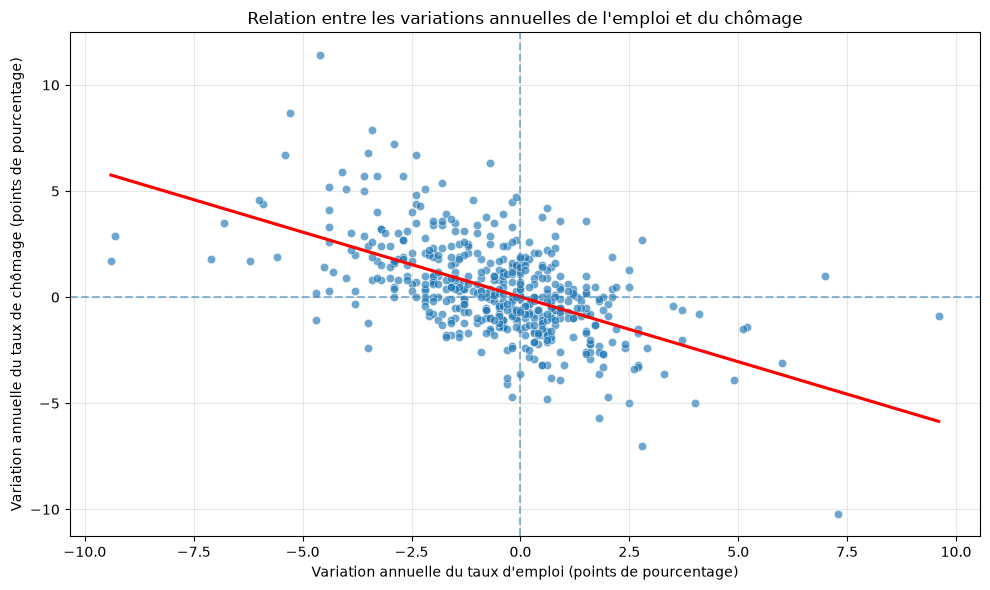

In [122]:
# Create a scatter plot of annual changes
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_changes,
    x="Variation_emploi_pp",
    y="Variation_chomage_pp",
    alpha=0.65
)

# Add a linear trend line
sns.regplot(
    data=df_changes,
    x="Variation_emploi_pp",
    y="Variation_chomage_pp",
    scatter=False,
    ci=None,
    color="red"
)

# Add reference lines at zero
plt.axhline(0, linestyle="--", alpha=0.5)
plt.axvline(0, linestyle="--", alpha=0.5)

plt.title(
    "Relation entre les variations annuelles de l'emploi et du chômage"
)
plt.xlabel("Variation annuelle du taux d'emploi (points de pourcentage)")
plt.ylabel("Variation annuelle du taux de chômage (points de pourcentage)")
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the figure
plt.savefig(
    FIGURES_DIR / "employment_unemployment_changes_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [123]:
# Create a copy for directional classification
df_changes_classified = df_changes.copy()

# Classify the direction of each indicator
df_changes_classified["Direction_emploi"] = np.select(
    [
        df_changes_classified["Variation_emploi_pp"] > 0,
        df_changes_classified["Variation_emploi_pp"] < 0
    ],
    ["Hausse", "Baisse"],
    default="Stable"
)

df_changes_classified["Direction_chomage"] = np.select(
    [
        df_changes_classified["Variation_chomage_pp"] > 0,
        df_changes_classified["Variation_chomage_pp"] < 0
    ],
    ["Hausse", "Baisse"],
    default="Stable"
)

# Classify the relationship between the two directions
df_changes_classified["Type_evolution"] = np.select(
    [
        (
            (df_changes_classified["Direction_emploi"] == "Hausse")
            & (df_changes_classified["Direction_chomage"] == "Baisse")
        )
        |
        (
            (df_changes_classified["Direction_emploi"] == "Baisse")
            & (df_changes_classified["Direction_chomage"] == "Hausse")
        ),

        (
            (df_changes_classified["Direction_emploi"] == "Hausse")
            & (df_changes_classified["Direction_chomage"] == "Hausse")
        )
        |
        (
            (df_changes_classified["Direction_emploi"] == "Baisse")
            & (df_changes_classified["Direction_chomage"] == "Baisse")
        )
    ],
    ["Evolutions opposees", "Evolutions dans le meme sens"],
    default="Au moins un indicateur stable"
)

# Count observations by category
direction_counts = (
    df_changes_classified["Type_evolution"]
    .value_counts()
    .rename_axis("Type_evolution")
    .reset_index(name="Nombre")
)

direction_counts["Pourcentage"] = (
    direction_counts["Nombre"] / len(df_changes_classified) * 100
)

display(direction_counts.round(2))

,Type_evolution,Nombre,Pourcentage
0,Evolutions opposees,329,66.33
1,Evolutions dans le meme sens,135,27.22
2,Au moins un indicateur stable,32,6.45


In [124]:
# Count each directional category by transition year
df_transition_directions = (
    df_changes_classified
    .groupby(["Annee", "Type_evolution"])
    .size()
    .unstack(fill_value=0)
)

# Calculate percentages within each transition
df_transition_percentages = (
    df_transition_directions
    .div(df_transition_directions.sum(axis=1), axis=0)
    * 100
)

print("NUMBER OF TERRITORIES BY TRANSITION")
display(df_transition_directions)

print("\nPERCENTAGE BY TRANSITION")
display(df_transition_percentages.round(2))

NUMBER OF TERRITORIES BY TRANSITION


Type_evolution,Au moins un indicateur stable,Evolutions dans le meme sens,Evolutions opposees
Annee,,,
2018,5,27,30
2019,10,19,33
2020,1,8,53
2021,4,13,45
2022,5,18,39
2023,3,11,48
2024,2,22,38
2025,2,17,43



PERCENTAGE BY TRANSITION


Type_evolution,Au moins un indicateur stable,Evolutions dans le meme sens,Evolutions opposees
Annee,,,
2018,8.06,43.55,48.39
2019,16.13,30.65,53.23
2020,1.61,12.90,85.48
2021,6.45,20.97,72.58
2022,8.06,29.03,62.90
2023,4.84,17.74,77.42
2024,3.23,35.48,61.29
2025,3.23,27.42,69.35


In [125]:
# Calculate the combined absolute magnitude of annual changes
df_changes_classified["Magnitude_totale_pp"] = (
    df_changes_classified["Variation_emploi_pp"].abs()
    + df_changes_classified["Variation_chomage_pp"].abs()
)

# Keep only transitions where both indicators moved in opposite directions
df_opposite_movements = df_changes_classified[
    df_changes_classified["Type_evolution"] == "Evolutions opposees"
].copy()

# Rank the most pronounced opposite movements
df_top_opposite_movements = (
    df_opposite_movements
    .sort_values("Magnitude_totale_pp", ascending=False)
    .head(15)
)

# Display the selected information
display(
    df_top_opposite_movements[
        [
            "Provinces/Préfectures",
            "Annee",
            "Variation_emploi_pp",
            "Variation_chomage_pp",
            "Magnitude_totale_pp"
        ]
    ].round(2)
)

,Provinces/Préfectures,Annee,Variation_emploi_pp,Variation_chomage_pp,Magnitude_totale_pp
131,Figuig,2021,7.3,-10.2,17.5
130,Figuig,2020,-4.6,11.4,16.0
282,Nador,2020,-5.3,8.7,14.0
34,Benslimane,2020,-9.3,2.9,12.2
134,Figuig,2024,-5.4,6.7,12.1
42,Berkane,2020,-3.4,7.9,11.3
306,Oued Ed-Dahab,2020,-9.4,1.7,11.1
386,Sidi Ifni,2020,-6.0,4.6,10.6
75,Chefchaouen,2021,9.6,-0.9,10.5
310,Oued Ed-Dahab,2024,-3.5,6.8,10.3


L'analyse des variations annuelles des taux d'emploi et de chômage sur 62 provinces et préfectures entre 2017 et 2025 met en évidence une relation généralement inverse entre les deux indicateurs. Sur les 496 transitions territoriales étudiées, 329 (66,33 %) présentent des évolutions opposées : une hausse du taux d'emploi accompagnée d'une baisse du taux de chômage, ou inversement. En revanche, 135 transitions (27,22 %) présentent des évolutions dans le même sens, tandis que 32 (6,45 %) comportent au moins un indicateur stable.

L'analyse par période révèle que la transition 2019–2020 présente la proportion la plus élevée d'évolutions opposées, avec 53 territoires sur 62 (85,48 %). Cette observation est cohérente avec la hausse généralisée du chômage constatée dans cette période.

Certaines évolutions territoriales se distinguent par leur ampleur. Figuig figure notamment parmi les territoires présentant les variations opposées les plus importantes, avec une baisse de 4,6 points du taux d'emploi et une hausse de 11,4 points du taux de chômage entre 2019 et 2020. La transition suivante présente le mouvement inverse : une hausse de 7,3 points du taux d'emploi et une baisse de 10,2 points du taux de chômage.

Ces résultats confirment l'existence d'une association généralement négative entre les variations des deux indicateurs. Toutefois, cette relation n'est pas systématique et ne permet pas d'établir un lien de causalité. Les observations doivent également être interprétées en tenant compte du caractère descriptif de l'analyse et de la répétition des observations pour chaque territoire.

In [126]:
# Export the classified annual changes
df_changes_classified.to_csv(
    PROCESSED_DIR / "employment_unemployment_annual_changes.csv",
    index=False,
    encoding="utf-8-sig"
)

# Export the global directional distribution
direction_counts.to_csv(
    PROCESSED_DIR / "employment_unemployment_direction_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# Export the directional distribution by annual transition
df_transition_directions.to_csv(
    PROCESSED_DIR / "employment_unemployment_directions_by_year.csv",
    encoding="utf-8-sig"
)

print("Comparative analysis exports completed.")

print("\nFiles saved:")
print("- employment_unemployment_annual_changes.csv")
print("- employment_unemployment_direction_summary.csv")
print("- employment_unemployment_directions_by_year.csv")

Comparative analysis exports completed.

Files saved:
- employment_unemployment_annual_changes.csv
- employment_unemployment_direction_summary.csv
- employment_unemployment_directions_by_year.csv
